# Phân loại cảm xúc review phim IMDb bằng LSTM

**Đề số 3** — Embedding + LSTM + Linear; mở rộng GRU, BiLSTM, GloVe.
**Nhóm:** Thư (leader), Bảo, Đại.

Notebook này **chỉ đọc kết quả** trong `experiments/` và `data/sample/`, không train lại. Section nào chưa có file sẽ hiện dòng ⏳ ghi rõ đang chờ ai.

| Section | Nội dung | Mục báo cáo |
| :--- | :--- | :--- |
| 1 | Vấn đề và phạm vi | 1 |
| 2 | Dữ liệu và EDA | 2 |
| 3 | Baseline | 6 |
| 4 | Mô hình | 3 |
| 5 | Theo dõi quá trình huấn luyện | 3 |
| 6 | Đánh giá, so sánh với baseline | 6 |
| 7 | Phân tích lỗi | 7 |
| 8 | Giải thích mô hình | 7 |
| 9 | Demo | 5 |
| 10 | Giới hạn | 7 |

Cách cài đặt và chạy lại toàn bộ (mục 4 của báo cáo): xem `README.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
EXP, RES, PLOTS = ROOT / "experiments", ROOT / "experiments" / "results", ROOT / "experiments" / "plots"

# Tên thư mục thí nghiệm theo docs/MODELS.md
MODELS = {
    "lstm": "M1 LSTM",
    "gru": "M2 GRU",
    "bilstm": "M3 BiLSTM",
    "bilstm_glove_frozen": "M4a BiLSTM + GloVe (đóng băng)",
    "bilstm_glove_ft": "M4b BiLSTM + GloVe (fine-tune)",
    "bilstm_attention": "B BiLSTM + attention pooling",
}
SEEDS = [42, 123, 2025]
BEST_EXP = None  # None = tự chọn theo val acc (section 6); hoặc ghi tên, ví dụ "bilstm_glove_ft"

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def rel(p: Path) -> str:
    return p.relative_to(ROOT).as_posix()


def waiting(p: Path, who: str) -> None:
    display(Markdown(f"> ⏳ Chưa có `{rel(p)}` — chờ {who}."))


def read_json(p: Path):
    return json.loads(p.read_text(encoding="utf-8"))


def show_img(p: Path, who: str, width: int = 760) -> None:
    display(Image(filename=str(p), width=width)) if p.exists() else waiting(p, who)


def metrics_from_pred(df: pd.DataFrame) -> dict:
    # Metric từ file dự đoán (cột label, pred, prob theo hợp đồng ở docs/TASKS.md §4).
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    return {
        "n": len(df),
        "accuracy": accuracy_score(df["label"], df["pred"]),
        "macro_f1": f1_score(df["label"], df["pred"], average="macro"),
        "roc_auc": roc_auc_score(df["label"], df["prob"]),
    }


def pred_file(exp: str, split: str) -> Path:
    return RES / exp / f"predictions_{split}.csv"


def best_seed(exp: str) -> int:
    # seed có val acc cao nhất của một thí nghiệm
    accs = {s: read_json(m)["best_val_acc"] for s in SEEDS
            if (m := RES / exp / f"seed_{s}" / "metrics.json").exists()}
    return max(accs, key=accs.get)

print("ROOT =", ROOT)

ROOT = D:\MON_HOC\Nam-3-HK1\DOT-1\DL\LSTM_PJ


## 1. Vấn đề và phạm vi

- **Bài toán:** phân loại nhị phân cảm xúc review phim tiếng Anh: tích cực (1) hoặc tiêu cực (0).
- **Dữ liệu:** IMDb Large Movie Review Dataset (Maas et al., 2011): 25.000 review train và 25.000 review test, cân bằng nhãn. Review tiêu cực có điểm ≤ 4, tích cực có điểm ≥ 7; không có review trung tính (5–6).
- **Mô hình bắt buộc:** Embedding → LSTM → Linear. **Mở rộng:** GRU, BiLSTM, BiLSTM + GloVe (đóng băng / fine-tune), thử độ dài cắt `max_len` 200/400/600.
- **Baseline:** majority class và TF-IDF (1–2 gram) + Logistic Regression.
- **Thước đo chính:** accuracy (dữ liệu cân bằng); kèm macro-F1, ROC-AUC, confusion matrix. Chọn checkpoint và early stopping theo **val accuracy**.
- **Ngoài phạm vi:** review trung tính, đa ngôn ngữ, mô hình Transformer (chỉ trích số DistilBERT từ Lab 3 để tham chiếu).

## 2. Dữ liệu và EDA

### 2.1 Chia tập và làm sạch

- Val tách từ train gốc **theo phim** (StratifiedGroupKFold 10 fold, seed 42, fold 0), để một phim không nằm ở cả train và val. Dùng lại split của Lab 3 (`data/splits/train_val_split.json`).
- Loại review trùng nội dung (SHA-1 của văn bản đã làm sạch): trùng trong train/val giữ 1 bản; trùng giữa train/val và test bỏ bản ở train/val, **giữ nguyên test 25.000**.
- Bỏ review train/val của phim cũng có trong test (`tt0406816`).

In [2]:
st = read_json(RES / "data_prep" / "prepare_stats.json")
splits = ["train", "val", "test"]
tbl = pd.DataFrame({
    "ban đầu": st["inputs"],
    "trùng trong split": st["removed_within_split"],
    "trùng với test": st["removed_cross_split"],
    "phim trùng test": {k: v for k, v in st["removed_movie_leak"].items() if k in splits},
    "còn lại": st["outputs"],
}).reindex(splits).fillna(0).astype(int)
display(tbl)
c = st["contract"]
print(f"Tổng {c['n_rows']:,} review; tỉ lệ nhãn 1: {c['pos_share_by_split']}")
print(f"Kiểm rò rỉ: trùng hash train/val–test = {c['hash_overlap_trainval_test']}, "
      f"phim chung train–val = {c['movie_overlap_train_val']}, train–test = {c['movie_overlap_train_test']}")
print(f"Review test trùng nội dung với train gốc: {st['test_reviews_also_in_train']} (báo thêm kết quả test khi bỏ nhóm này, section 6)")

,ban đầu,trùng trong split,trùng với test,phim trùng test,còn lại
train,22499,87,106,2,22304
val,2501,11,17,0,2473
test,25000,0,0,0,25000


Tổng 49,777 review; tỉ lệ nhãn 1: {'test': 0.5, 'train': 0.502511, 'val': 0.499393}
Kiểm rò rỉ: trùng hash train/val–test = 0, phim chung train–val = 0, train–test = 0
Review test trùng nội dung với train gốc: 123 (báo thêm kết quả test khi bỏ nhóm này, section 6)


### 2.2 Thống kê tổng quan

In [3]:
summary = pd.read_csv(RES / "eda" / "eda_summary.csv").set_index("split")
display(summary[["n_reviews", "n_pos", "n_neg", "n_movies", "len_mean", "len_median", "len_p95",
                 "len_pct_over_200", "len_pct_over_400", "pct_with_br", "pct_with_negation"]].round(1))

,n_reviews,n_pos,n_neg,n_movies,len_mean,len_median,len_p95,len_pct_over_200,len_pct_over_400,pct_with_br,pct_with_negation
split,,,,,,,,,,,
train,22304,11208,11096,3081,231.8,173.0,593.0,40.8,13.2,58.7,89.5
val,2473,1235,1238,343,231.3,173.0,589.2,41.6,12.6,58.7,89.4
test,25000,12500,12500,3581,226.3,170.0,576.0,39.8,12.2,58.1,89.1


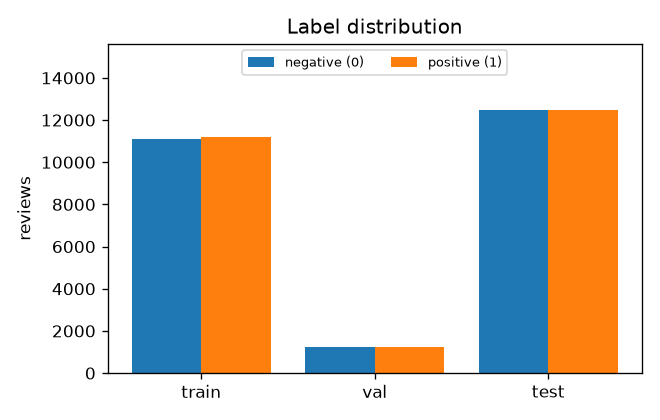

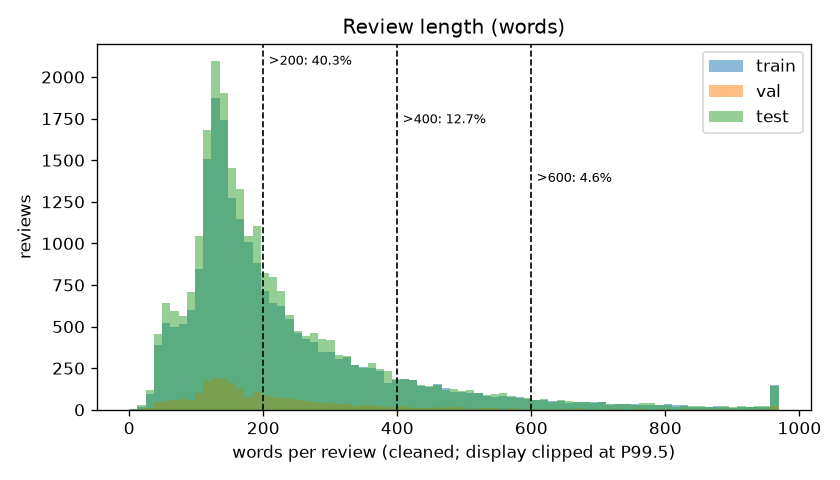

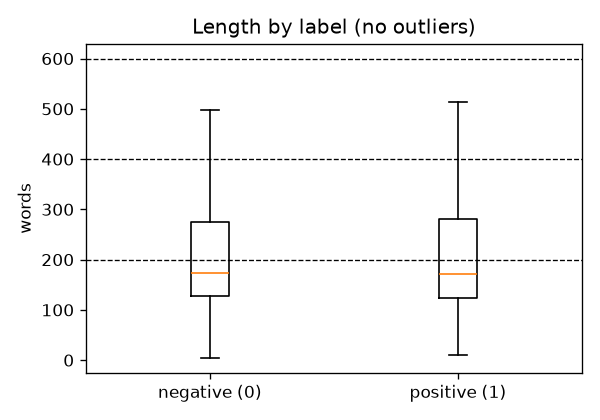

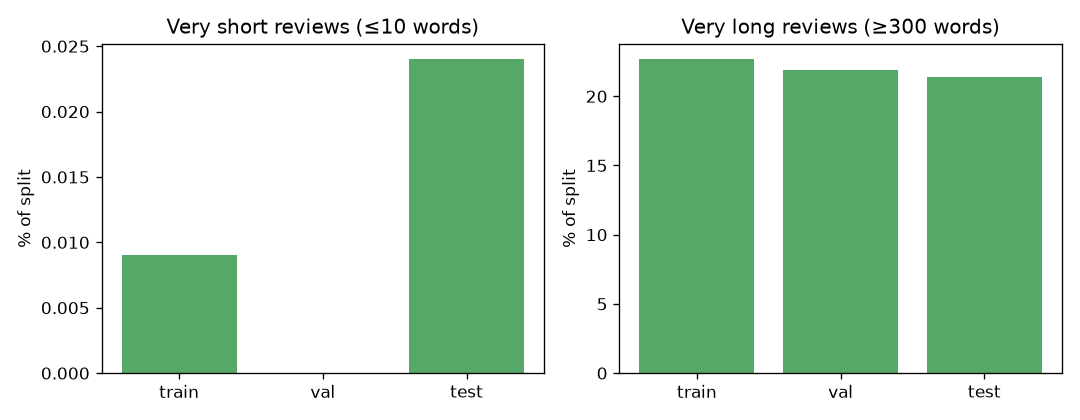

In [4]:
for name in ["label_distribution", "length_hist", "length_by_label", "length_extremes"]:
    show_img(PLOTS / "eda" / f"eda_{name}.png", "Bảo (B2)")

**Nhận xét độ dài:** khoảng 41% review train dài hơn 200 từ và khoảng 13% dài hơn 400 từ. Vì vậy chọn `max_len` ảnh hưởng tới việc mô hình có đọc được câu kết luận ở cuối review hay không. Thí nghiệm `max_len` 200/400/600 ở section 6 kiểm tra điều này.

### 2.3 Phủ định, từ phổ biến, điểm số

,split,label,n_reviews,n_with_negation,pct_with_negation
0,train,0,11096,10381,93.556
1,train,1,11208,9572,85.403
2,val,0,1238,1161,93.780
3,val,1,1235,1049,84.939
4,test,0,12500,11611,92.888
5,test,1,12500,10662,85.296


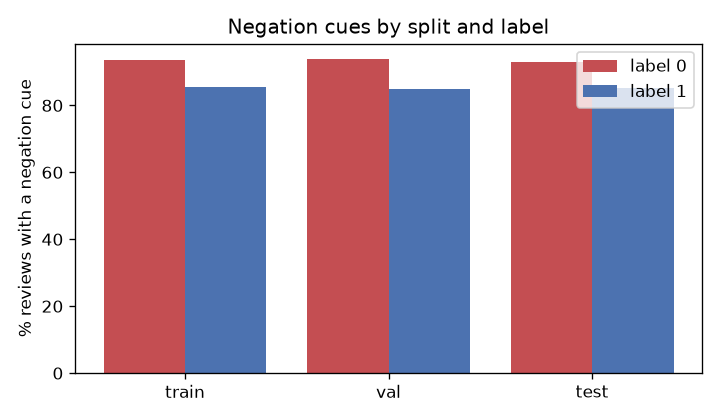

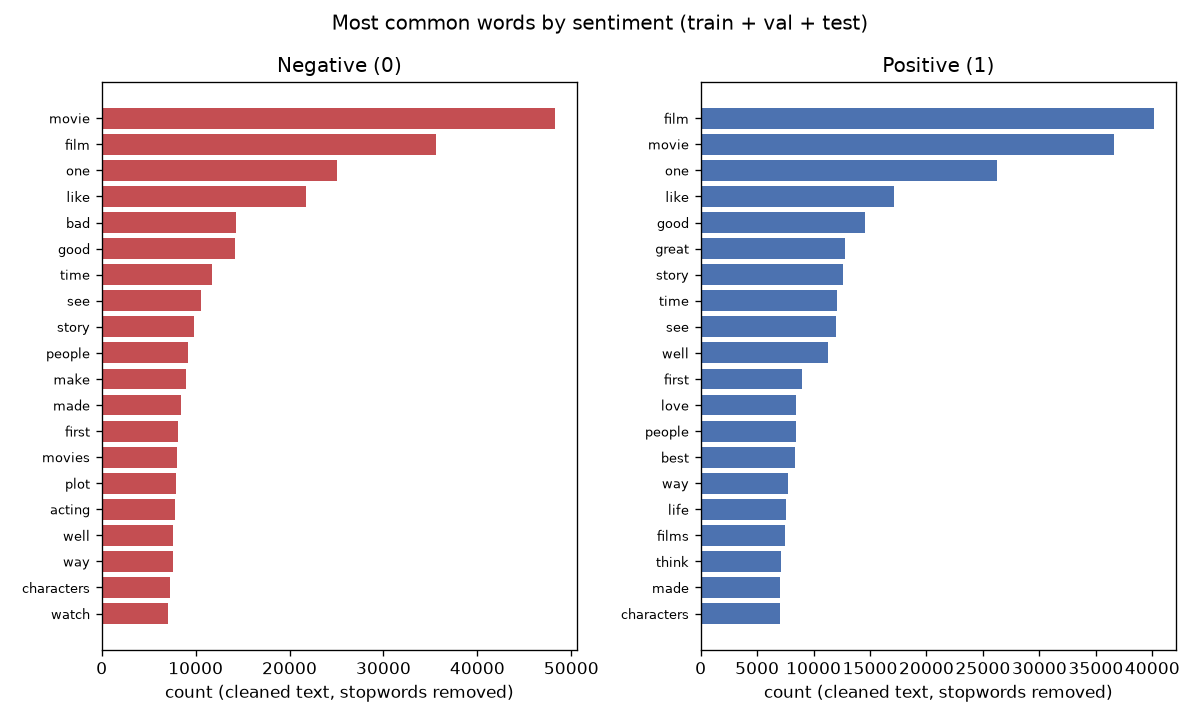

,test,train,val
rating,,,
1,5022,4502,526
2,2302,2034,221
3,2541,2150,239
4,2635,2410,252
7,2307,2258,233
8,2850,2690,310
9,2344,2024,223
10,4999,4236,469


In [5]:
display(pd.read_csv(RES / "eda" / "eda_negation.csv"))
show_img(PLOTS / "eda" / "eda_negation_share.png", "Bảo (B2)")
show_img(PLOTS / "eda" / "eda_top_words.png", "Bảo (B2)")
display(pd.read_csv(RES / "eda" / "eda_ratings.csv").set_index("rating"))

- Phủ định xuất hiện ở khoảng 89% review, ở cả hai nhãn. Do đó không thể dựa riêng vào từ "not" để đoán nhãn. Mô hình tuần tự phải học được phủ định đổi nghĩa từ đi sau nó.
- Không có điểm 5–6, nên mô hình chưa từng thấy review trung tính (xem giới hạn, section 10).

### 2.4 Vấn đề chất lượng dữ liệu và mẫu dữ liệu

In [6]:
display(pd.read_csv(RES / "eda" / "eda_quality_issues.csv"))
sample = pd.read_csv(ROOT / "data" / "sample" / "sample_100.csv")
print(sample.shape, "— data/sample/sample_100.csv")
display(sample.head(5))

,scope,split,check,count,detail
0,split,train,còn thẻ HTML khác <br /> trong text_clean,7,"ví dụ <i>, </i> — clean_text chỉ bỏ <br />"
1,split,test,review trùng nội dung trong split (bản thừa),201,giữ 1 bản; test cố ý không xoá
2,split,test,còn thẻ HTML khác <br /> trong text_clean,3,"ví dụ <i>, </i> — clean_text chỉ bỏ <br />"
3,global,test,"review trùng nội dung trong test (bản thừa, giữ nguyên)",201,NaN


(100, 6) — data/sample/sample_100.csv


,uid,text,label,case_type,rating,source_file
0,test_neg_1816,"This is the first and as far as I can tell, the only completed production of ""Heart of Darkness"" ever released. Prio...",0,long_review,4,test
1,test_neg_2102,"Snakes on a Train starts as Mexican couple Brujo (A.J. Castro) & Alma (Julia Ruiz) cross the boarder into the US, th...",0,long_review,3,test
2,test_neg_4829,Speed which I believe is direct copy of the Hollywood movie Cellular (I haven't watched this one) gives an impressio...,0,long_review,3,test
3,test_neg_5203,"As a huge fan of the original Operation Delta Force, I thought I'd pick this film up. I figured it couldn't be too b...",0,long_review,1,test
4,test_neg_6360,Critters 3 starts on the open road as Clifford (John Calvin) his teenage daughter Annie (Aimee Brooks) & his young s...,0,long_review,4,test


## 3. Baseline

- **M0a Majority:** luôn đoán nhãn nhiều nhất trong train.
- **M0b TF-IDF (1–2 gram, `min_df=2`) + Logistic Regression:** chọn `C` trên val trong lưới {0,01; 0,1; 1; 10; 30; 100}.

,n,accuracy,macro_f1,roc_auc
M0a Majority,2473.0,0.4994,0.3331,0.5000
M0b TF-IDF + LR (C=10),2473.0,0.8985,0.8985,0.9623


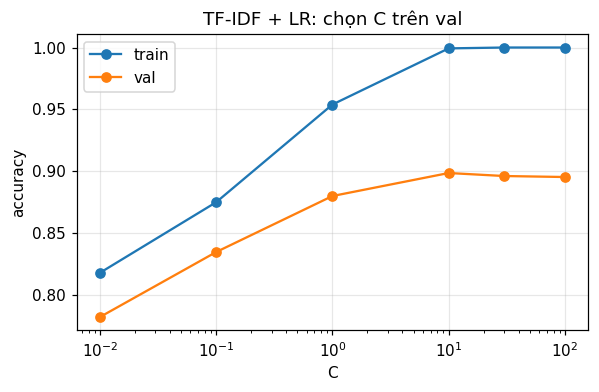

Confusion matrix M0b trên val (hàng = thật 0/1, cột = đoán 0/1):
 [[1093  145]
 [ 106 1129]]


In [7]:
bm = read_json(RES / "baseline" / "metrics.json")
rows = {"M0a Majority": bm["M0a_majority"]["val"], f"M0b TF-IDF + LR (C={bm['M0b_tfidf_lr']['selected_C']:g})": bm["M0b_tfidf_lr"]["val"]}
display(pd.DataFrame({k: {m: v[m] for m in ["n", "accuracy", "macro_f1", "roc_auc"]} for k, v in rows.items()}).T.round(4))

grid = pd.read_csv(RES / "baseline" / "c_grid.csv")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(grid["C"], grid["train_accuracy"], "o-", label="train")
ax.plot(grid["C"], grid["val_accuracy"], "o-", label="val")
ax.set(xscale="log", xlabel="C", ylabel="accuracy", title="TF-IDF + LR: chọn C trên val")
ax.legend(); plt.show()

cm = np.array(bm["M0b_tfidf_lr"]["val"]["confusion_matrix"]["matrix"])
print("Confusion matrix M0b trên val (hàng = thật 0/1, cột = đoán 0/1):\n", cm)

Baseline TF-IDF + LR đạt **val acc ≈ 0,899**, nhưng train acc ≈ 0,999 nên overfit khoảng 10 điểm. Đây là mốc mô hình LSTM phải vượt.

## 4. Mô hình

Cùng một khung `SentimentRNN`: **Embedding → RNN → lấy trạng thái ẩn cuối → Dropout → Linear → 1 logit** (BCEWithLogitsLoss). Chỉ thay loại RNN, số chiều và embedding:

| Mã | Mô hình | Embedding | RNN |
| :--- | :--- | :--- | :--- |
| M1 | LSTM (bắt buộc) | học từ đầu, 100d | LSTM 1 chiều, 128 |
| M2 | GRU | học từ đầu, 100d | GRU 1 chiều, 128 |
| M3 | BiLSTM | học từ đầu, 100d | LSTM 2 chiều, 128 × 2 |
| M4a | BiLSTM + GloVe | GloVe 100d, đóng băng | LSTM 2 chiều, 128 × 2 |
| M4b | BiLSTM + GloVe | GloVe 100d, fine-tune | LSTM 2 chiều, 128 × 2 |

Mỗi cấu hình chạy 3 seed (42, 123, 2025), báo mean ± std. Chi tiết siêu tham số: `docs/MODELS.md`, `configs/`.

In [8]:
rows = []
for exp, name in MODELS.items():
    p = RES / exp / "summary.json"
    if p.exists():
        rows.append(pd.json_normalize(read_json(p)).assign(model=name).set_index("model"))
    else:
        waiting(p, "Đại (D6)")
if rows:
    display(pd.concat(rows).T)

model,M1 LSTM,M2 GRU,M3 BiLSTM,M4a BiLSTM + GloVe (đóng băng),M4b BiLSTM + GloVe (fine-tune),B BiLSTM + attention pooling
exp_name,lstm,gru,bilstm,bilstm_glove_frozen,bilstm_glove_ft,bilstm_attention
n_seeds,3,3,3,3,3,3
seeds,"[42, 123, 2025]","[42, 123, 2025]","[42, 123, 2025]","[42, 123, 2025]","[42, 123, 2025]","[42, 123, 2025]"
parameters.total,2617889,2588449,2735777,2735777,2735777,2768802
parameters.trainable,2617889,2588449,2735777,235777,2735777,2768802
parameters.embedding_trainable,True,True,True,False,True,True
best_val_acc.mean,0.8609,0.8827,0.8629,0.8776,0.867,0.8826
best_val_acc.std,0.0033,0.0045,0.0093,0.0031,0.0065,0.0058
best_val_acc.formatted,86.09 ± 0.33%,88.27 ± 0.45%,86.29 ± 0.93%,87.76 ± 0.31%,86.70 ± 0.65%,88.26 ± 0.58%
val_loss_at_best.mean,0.4415,0.3372,0.3906,0.3137,0.3104,0.2908


## 5. Theo dõi quá trình huấn luyện

Mỗi epoch ghi `history.csv`: `epoch, train_loss, train_acc, val_loss, val_acc, val_f1, grad_norm_mean, lr, epoch_seconds`. Với mỗi cấu hình, chồng 3 seed lên cùng hình:

- **Loss và accuracy train/val:** đánh dấu epoch tốt nhất theo val acc.
- **Khoảng cách train acc − val acc:** cho thấy mức overfit.
- **Grad norm:** phát hiện nổ gradient.

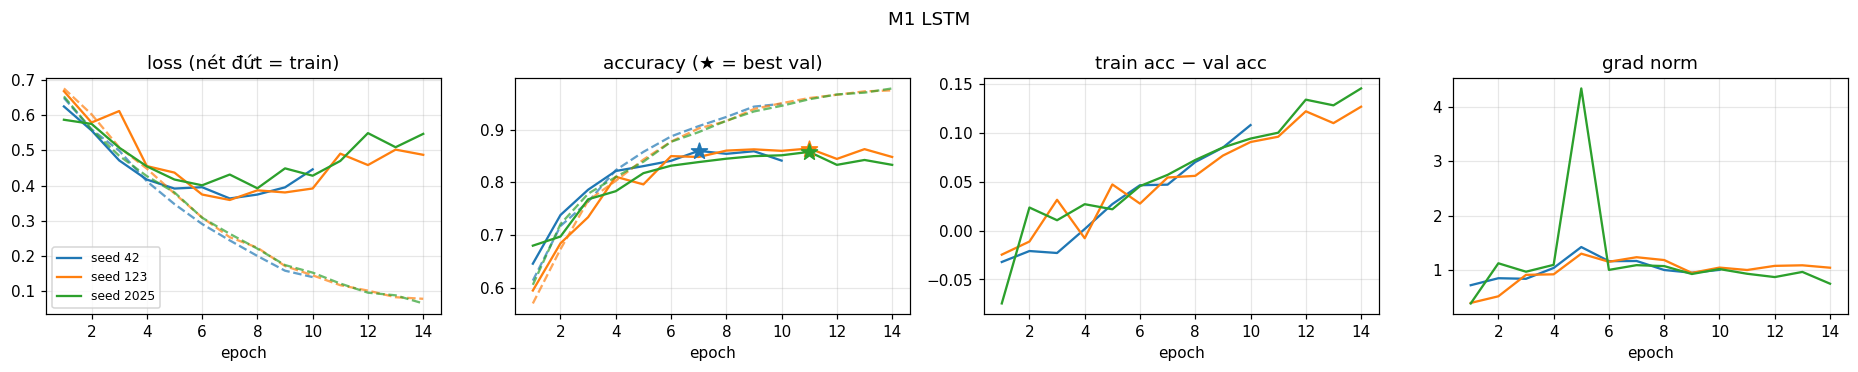

,best_epoch,stop_epoch,best_val_acc,val_loss@best,min_val_loss_epoch,train_minutes
seed,,,,,,
42,7,10,0.8601,0.3635,7,2.1280
123,11,14,0.8645,0.4909,7,3.0057
2025,11,14,0.8581,0.4702,8,2.9950


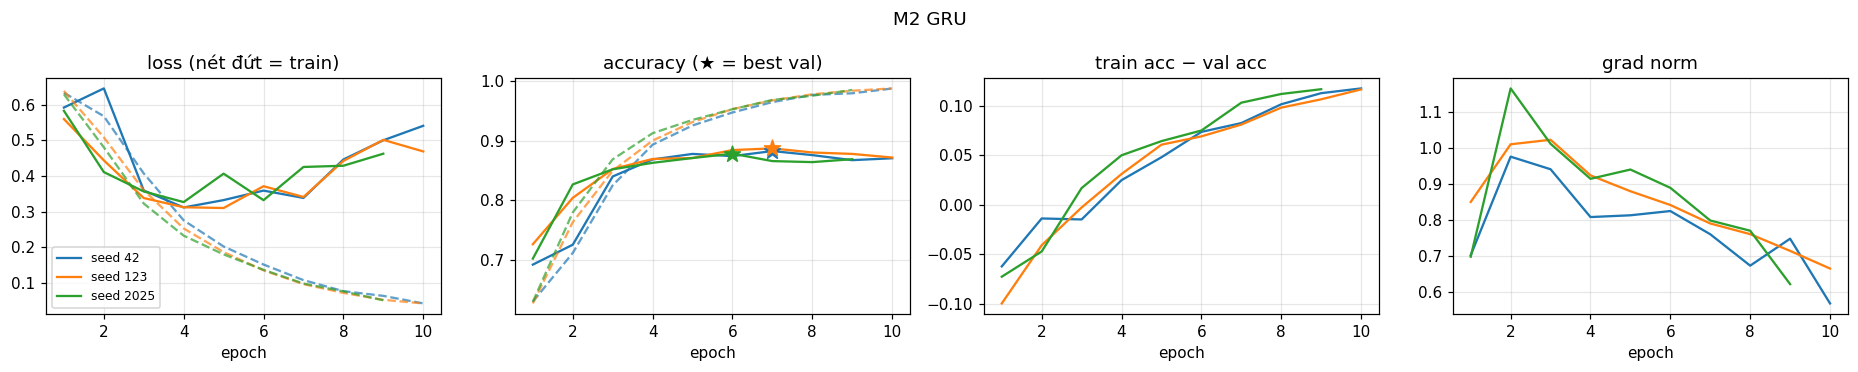

,best_epoch,stop_epoch,best_val_acc,val_loss@best,min_val_loss_epoch,train_minutes
seed,,,,,,
42,7,10,0.8827,0.3384,4,2.1027
123,7,10,0.8872,0.3411,5,2.1198
2025,6,9,0.8783,0.3321,4,1.9125


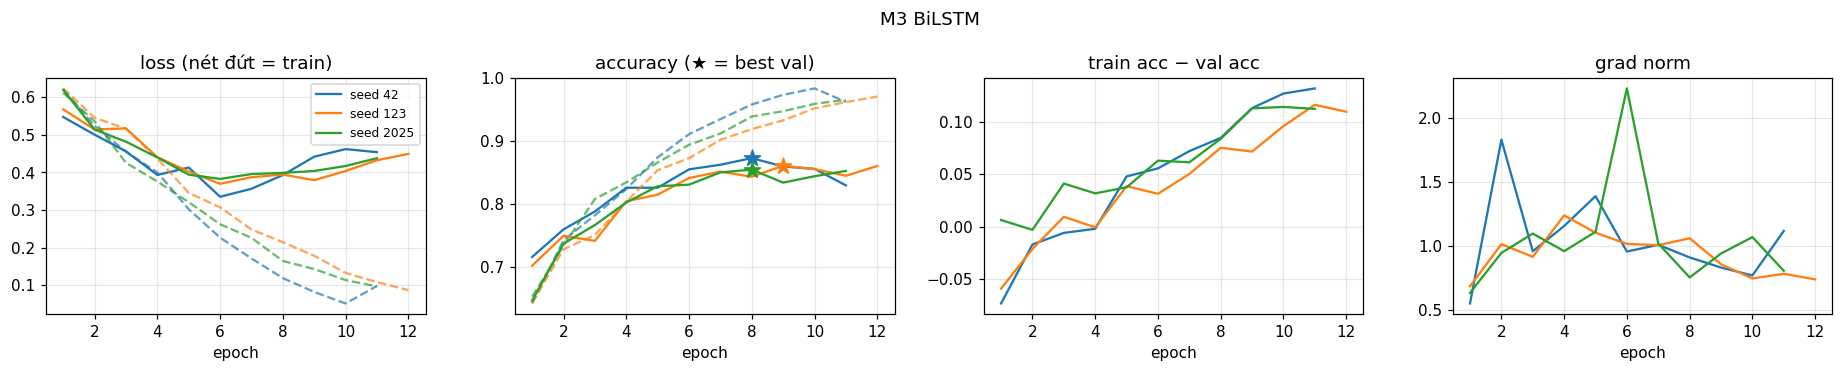

,best_epoch,stop_epoch,best_val_acc,val_loss@best,min_val_loss_epoch,train_minutes
seed,,,,,,
42,8,11,0.8730,0.3932,6,3.1113
123,9,12,0.8609,0.3796,6,3.4160
2025,8,11,0.8548,0.3989,6,3.1775


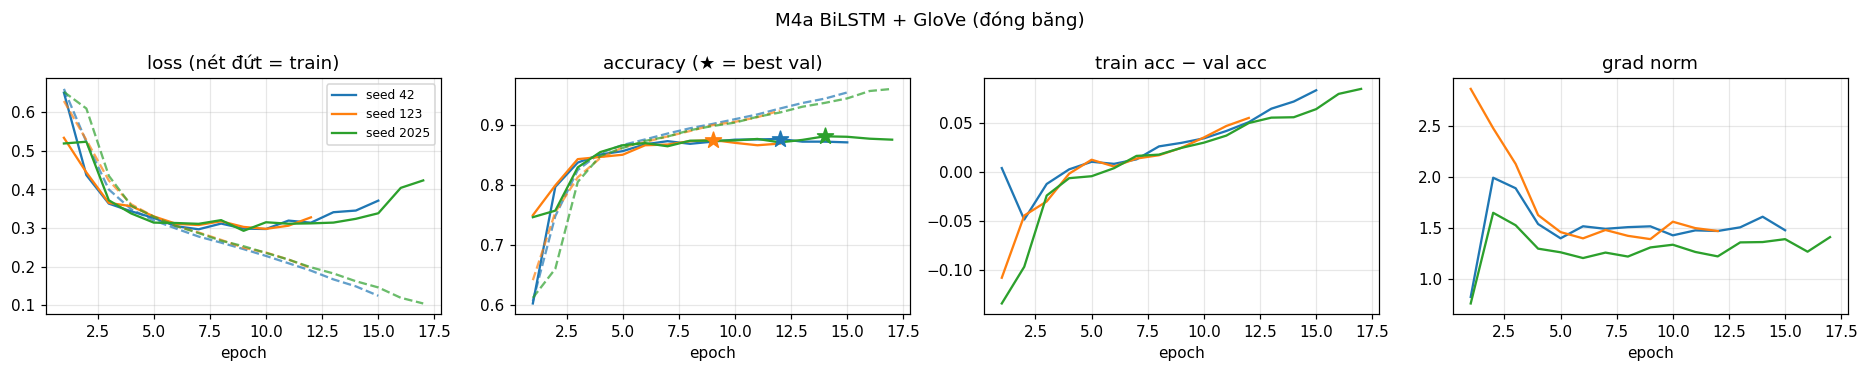

,best_epoch,stop_epoch,best_val_acc,val_loss@best,min_val_loss_epoch,train_minutes
seed,,,,,,
42,12,15,0.8767,0.314,7,3.8735
123,9,12,0.8751,0.303,10,3.1200
2025,14,17,0.8811,0.324,9,4.3687


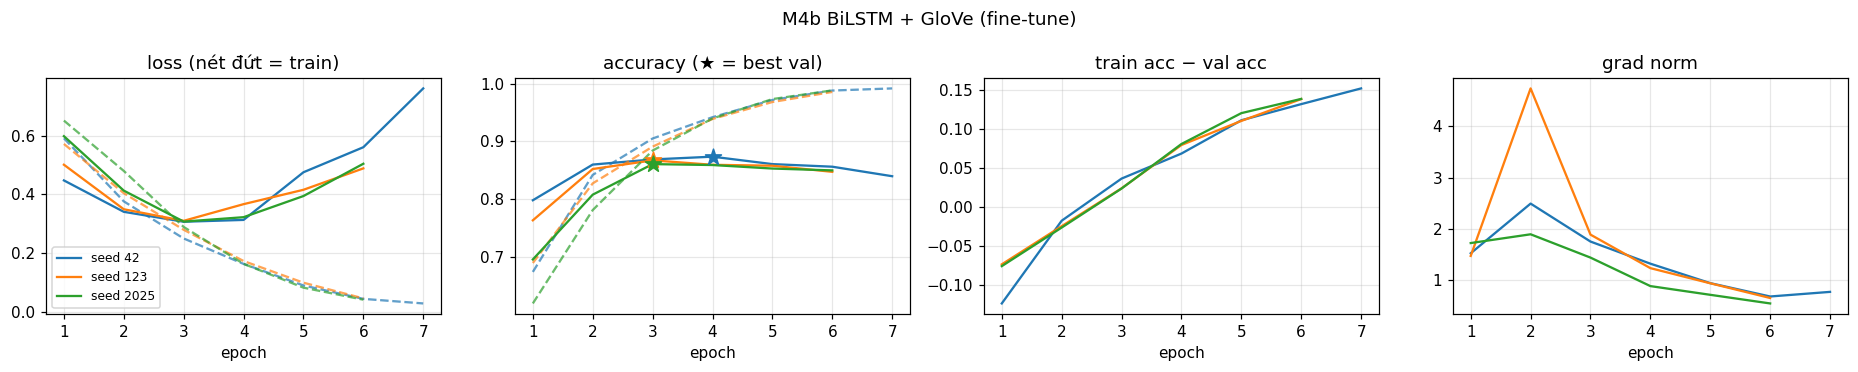

,best_epoch,stop_epoch,best_val_acc,val_loss@best,min_val_loss_epoch,train_minutes
seed,,,,,,
42,4,7,0.8734,0.3133,3,1.9847
123,3,6,0.8670,0.3102,3,1.7627
2025,3,6,0.8605,0.3076,3,1.7233


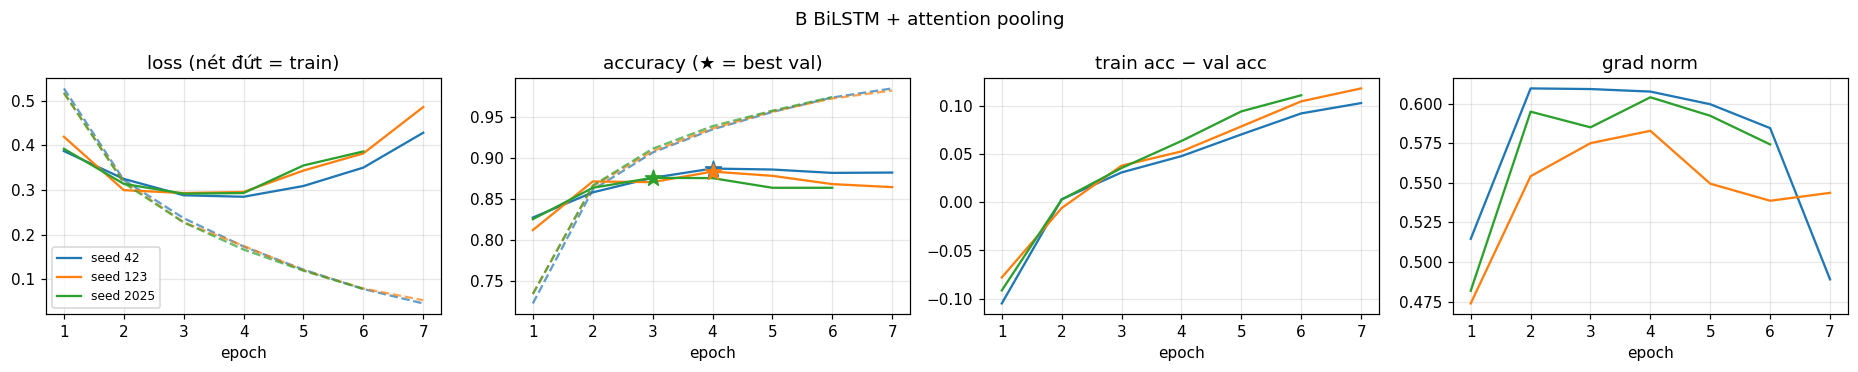

,best_epoch,stop_epoch,best_val_acc,val_loss@best,min_val_loss_epoch,train_minutes
seed,,,,,,
42,4,7,0.8876,0.2849,4,2.9387
123,4,7,0.8839,0.2956,3,3.0372
2025,3,6,0.8763,0.2918,3,2.5833


In [9]:
def find_history(exp, seed):
    # results/ được commit; runs/ nằm trong .gitignore nên chỉ có trên máy đã train
    for p in [RES / exp / f"seed_{seed}" / "history.csv", EXP / "runs" / exp / f"seed_{seed}" / "history.csv"]:
        if p.exists():
            return pd.read_csv(p)
    return None


def plot_curves(exp, name):
    hs = {s: find_history(exp, s) for s in SEEDS}
    hs = {s: h for s, h in hs.items() if h is not None}
    if not hs:
        waiting(RES / exp / "seed_<s>" / "history.csv", "Đại (D5–D6)")
        return None
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
    rows = []
    for s, h in hs.items():
        best = h.loc[h["val_acc"].idxmax()]
        l, = axes[0].plot(h["epoch"], h["train_loss"], "--", alpha=0.7)
        axes[0].plot(h["epoch"], h["val_loss"], "-", color=l.get_color(), label=f"seed {s}")
        axes[1].plot(h["epoch"], h["train_acc"], "--", color=l.get_color(), alpha=0.7)
        axes[1].plot(h["epoch"], h["val_acc"], "-", color=l.get_color())
        axes[1].scatter([best["epoch"]], [best["val_acc"]], color=l.get_color(), marker="*", s=120, zorder=3)
        axes[2].plot(h["epoch"], h["train_acc"] - h["val_acc"], color=l.get_color())
        axes[3].plot(h["epoch"], h["grad_norm_mean"], color=l.get_color())
        rows.append({"seed": s, "best_epoch": int(best["epoch"]), "stop_epoch": int(h["epoch"].max()),
                     "best_val_acc": best["val_acc"], "val_loss@best": best["val_loss"],
                     "min_val_loss_epoch": int(h.loc[h["val_loss"].idxmin(), "epoch"]),
                     "train_minutes": h["epoch_seconds"].sum() / 60})
    for ax, t in zip(axes, ["loss (nét đứt = train)", "accuracy (★ = best val)", "train acc − val acc", "grad norm"]):
        ax.set(title=t, xlabel="epoch")
    axes[0].legend(fontsize=8)
    fig.suptitle(name); plt.tight_layout(); plt.show()
    return pd.DataFrame(rows).set_index("seed").round(4)


for exp, name in MODELS.items():
    t = plot_curves(exp, name)
    if t is not None:
        display(t)

**Cách đọc:**
- Nếu `min_val_loss_epoch` sớm hơn `best_epoch` thì val loss đã tăng trong khi val acc vẫn tăng. Mô hình tự tin quá mức trên một số mẫu, nhưng số mẫu đúng vẫn tăng. Đây là lý do nhóm chọn checkpoint theo val acc thay vì val loss.
- Khoảng cách train − val tăng dần nghĩa là overfit.

**Nhận xét (6 mô hình × 3 seed, `max_len` = 400):**
- **Early stopping hoạt động đúng:** cả 18 lần chạy đều dừng trước trần 20 epoch (dừng ở epoch 6–17), checkpoint giữ ở epoch có val acc cao nhất.
- **Overfit nhanh:** tại epoch tốt nhất, train acc cao hơn val acc 2–10 điểm; sau đó val loss tăng rõ. Ở 12/18 lần chạy, val loss thấp nhất **sớm hơn** epoch có val acc cao nhất — đúng hiện tượng mô tả ở trên, xác nhận lựa chọn theo val acc.
- **Tốc độ hội tụ khác nhau theo kiến trúc:** attention và GloVe fine-tune tốt nhất ở epoch 3–4; GRU 6–7; LSTM 7–11 (không đều giữa các seed); GloVe đóng băng chậm nhất, 9–14, vì chỉ train 8,6% tham số.
- **Không có nổ gradient:** grad norm trung bình mỗi epoch lớn nhất là 4,74, dưới ngưỡng clipping 5,0; attention ổn định nhất (≤ 0,61).
- **GloVe đóng băng ít overfit nhất** (khoảng cách train − val 2–6 điểm), nhưng đổi lại hội tụ chậm.

experiments/plots/training/bilstm_attention_curves.png


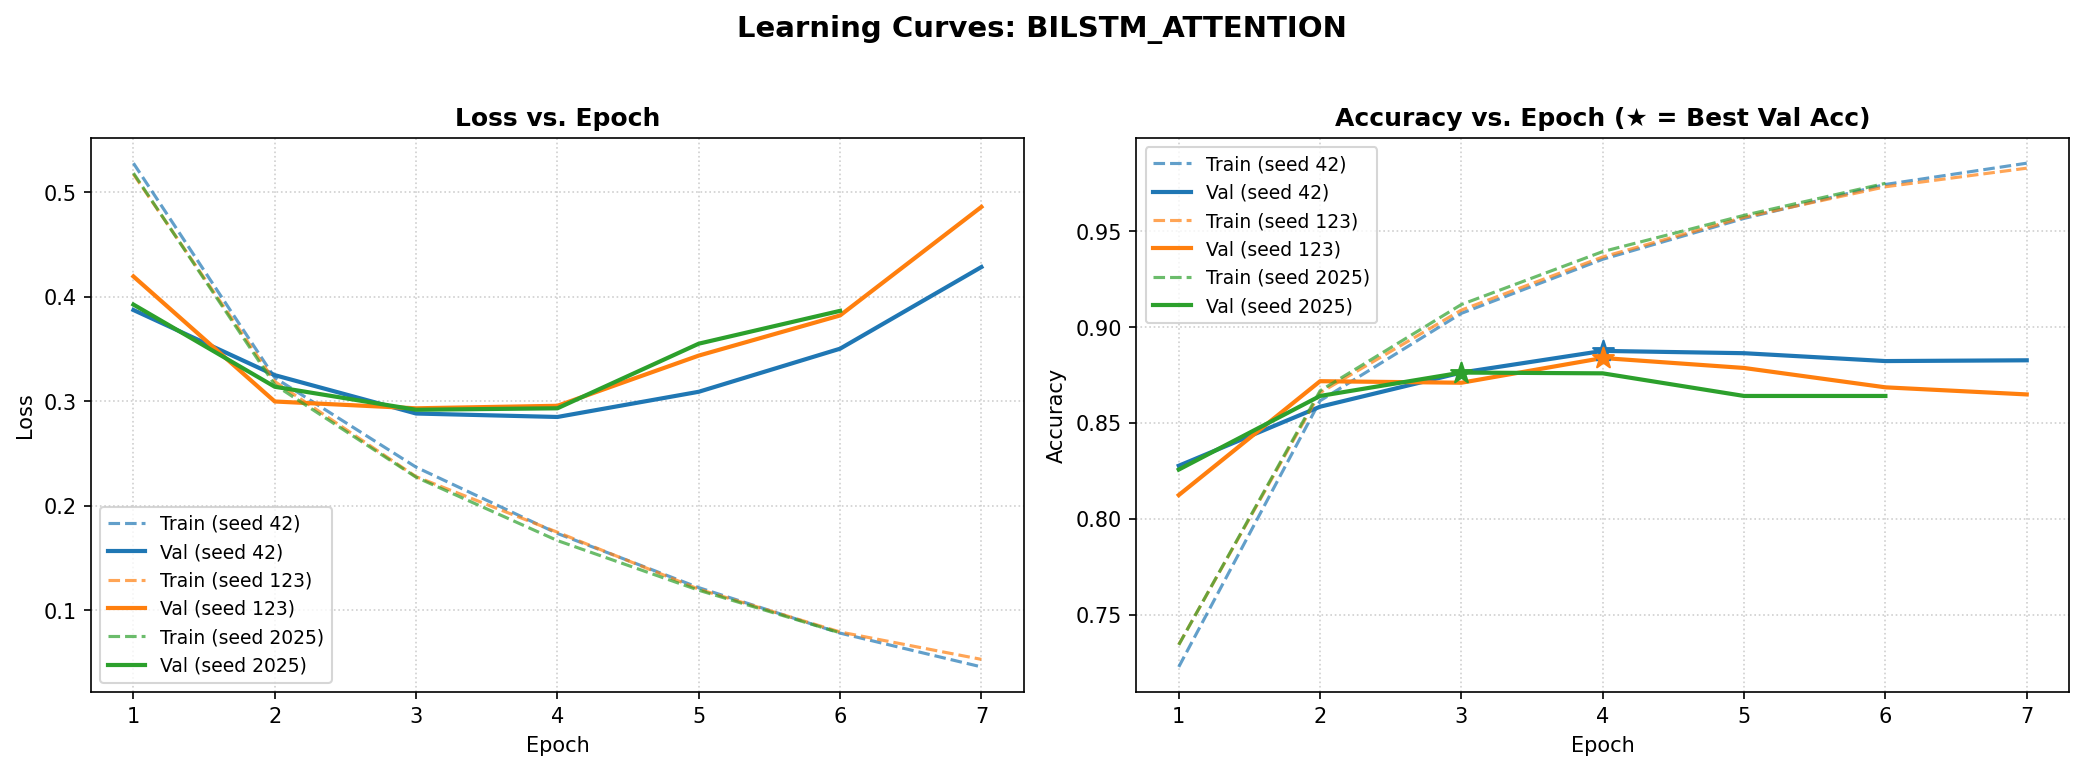

experiments/plots/training/bilstm_curves.png


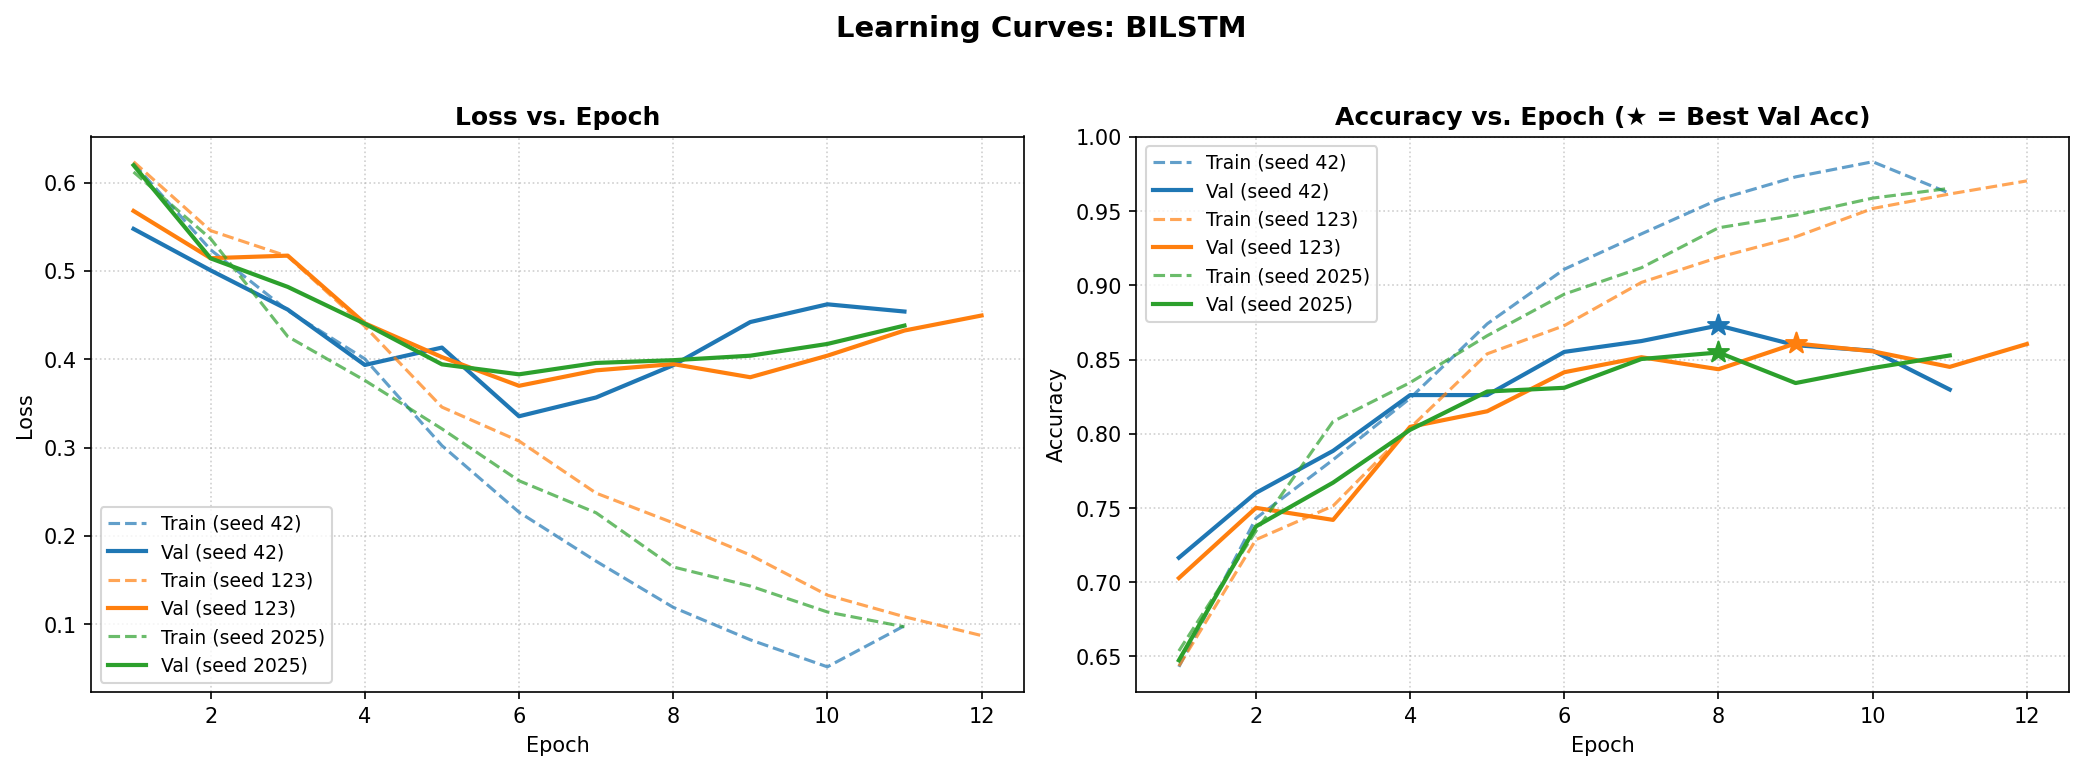

experiments/plots/training/bilstm_glove_frozen_curves.png


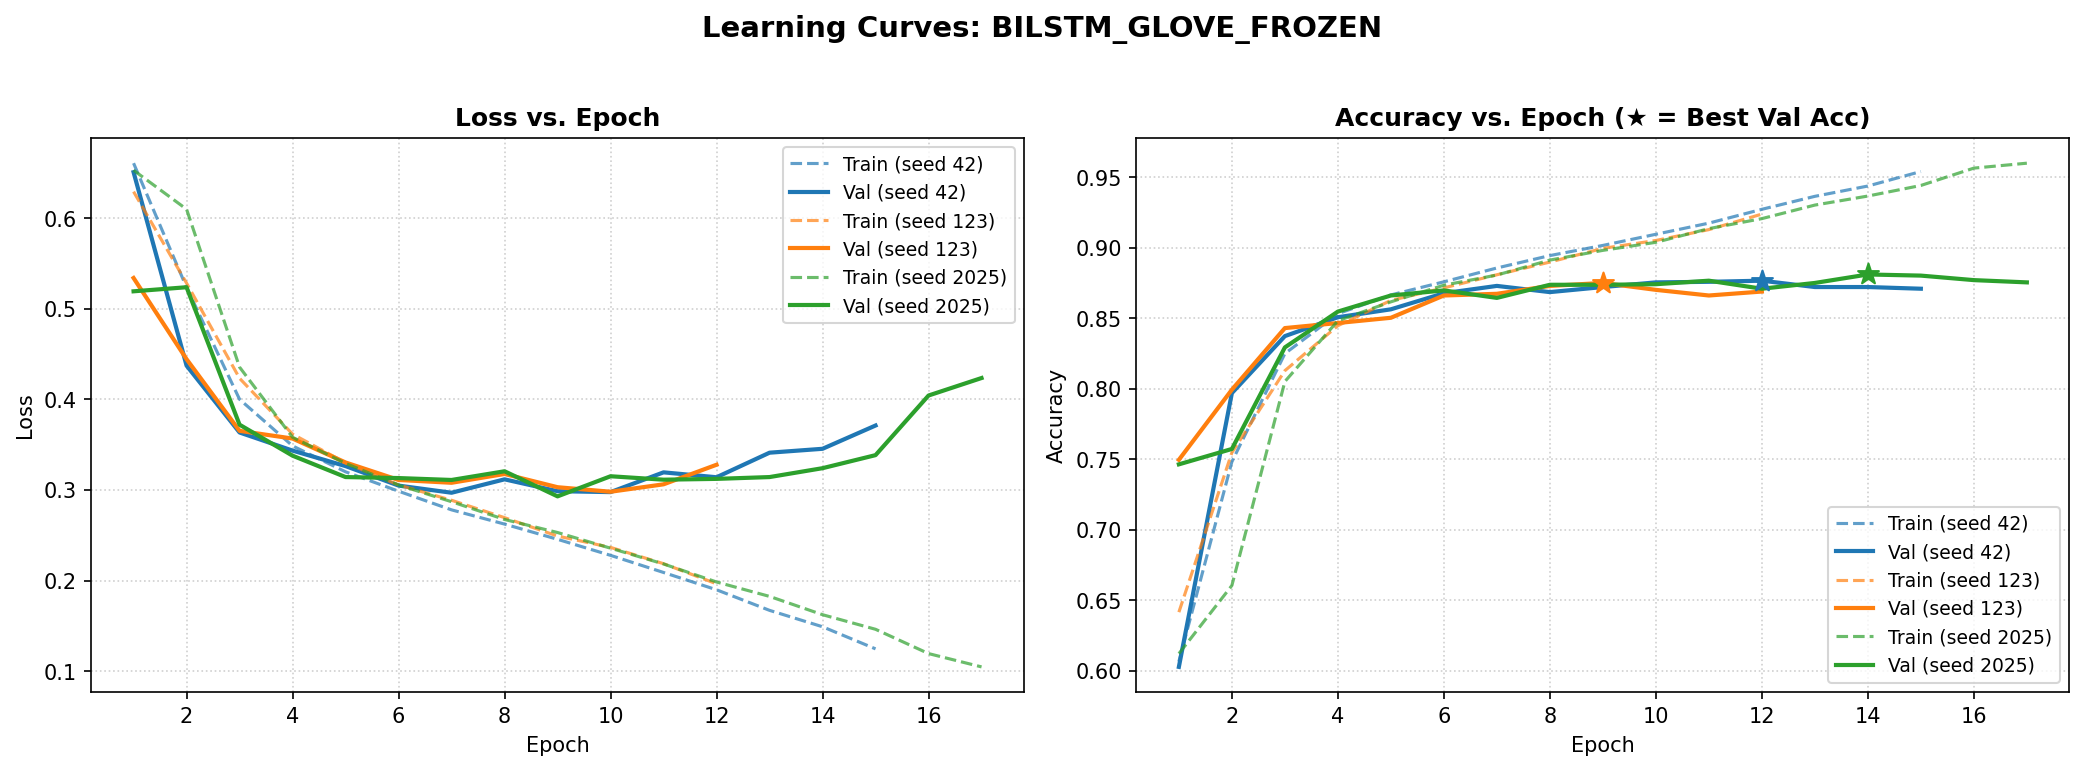

experiments/plots/training/bilstm_glove_ft_curves.png


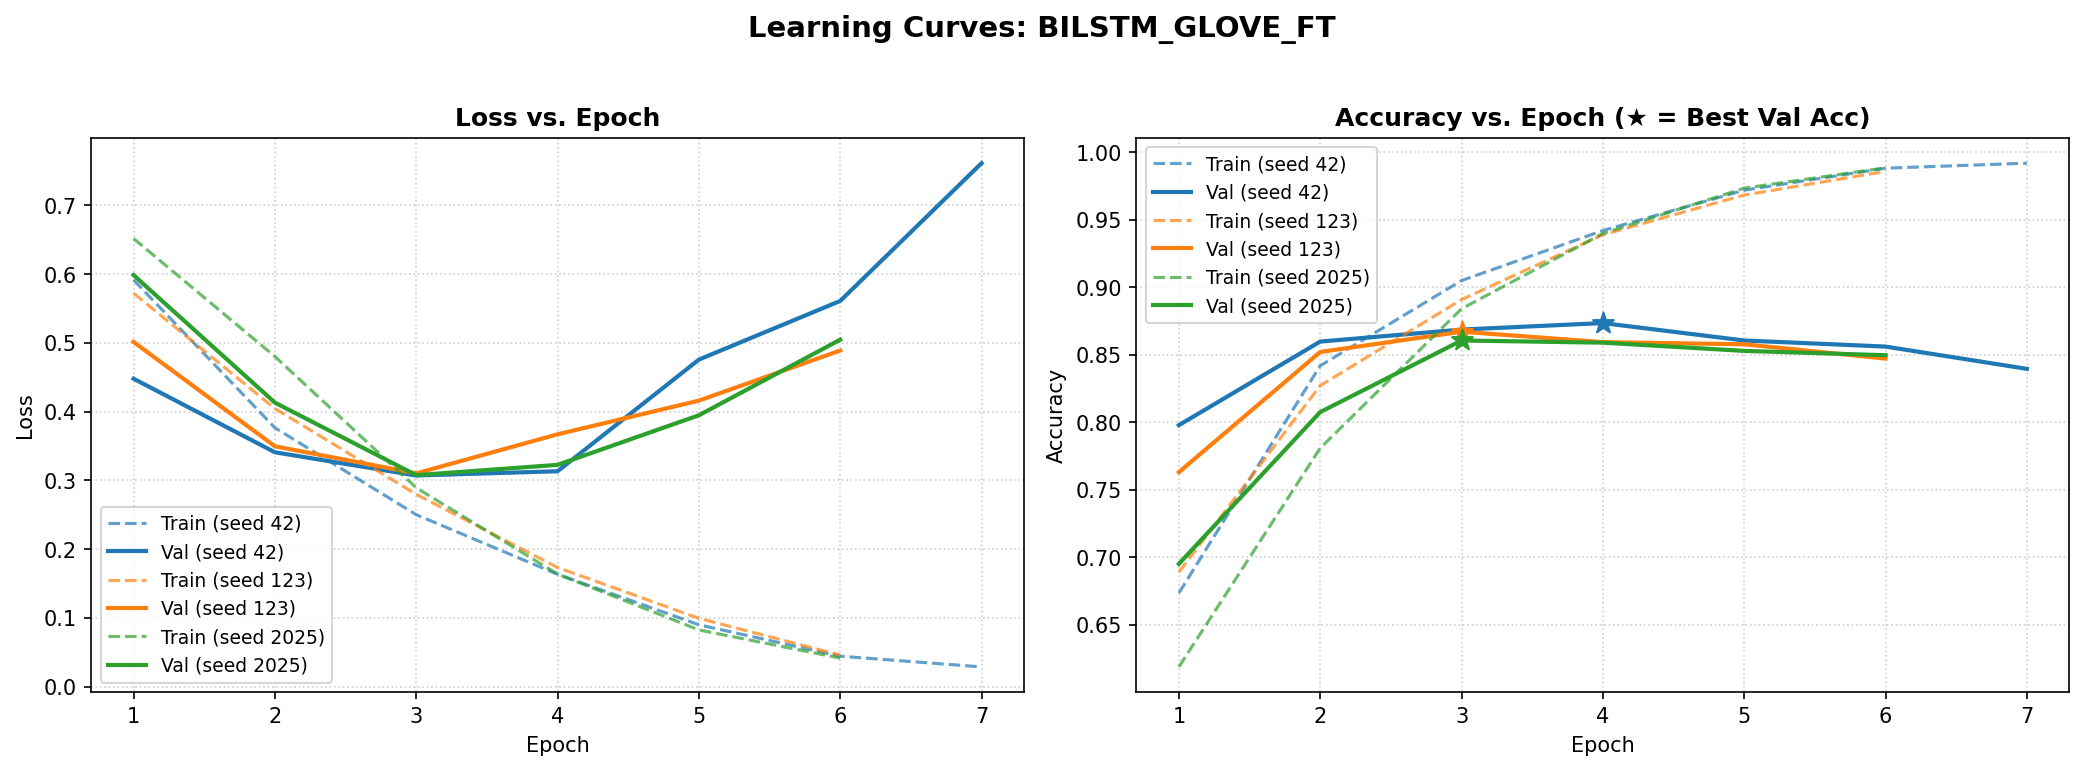

experiments/plots/training/gru_curves.png


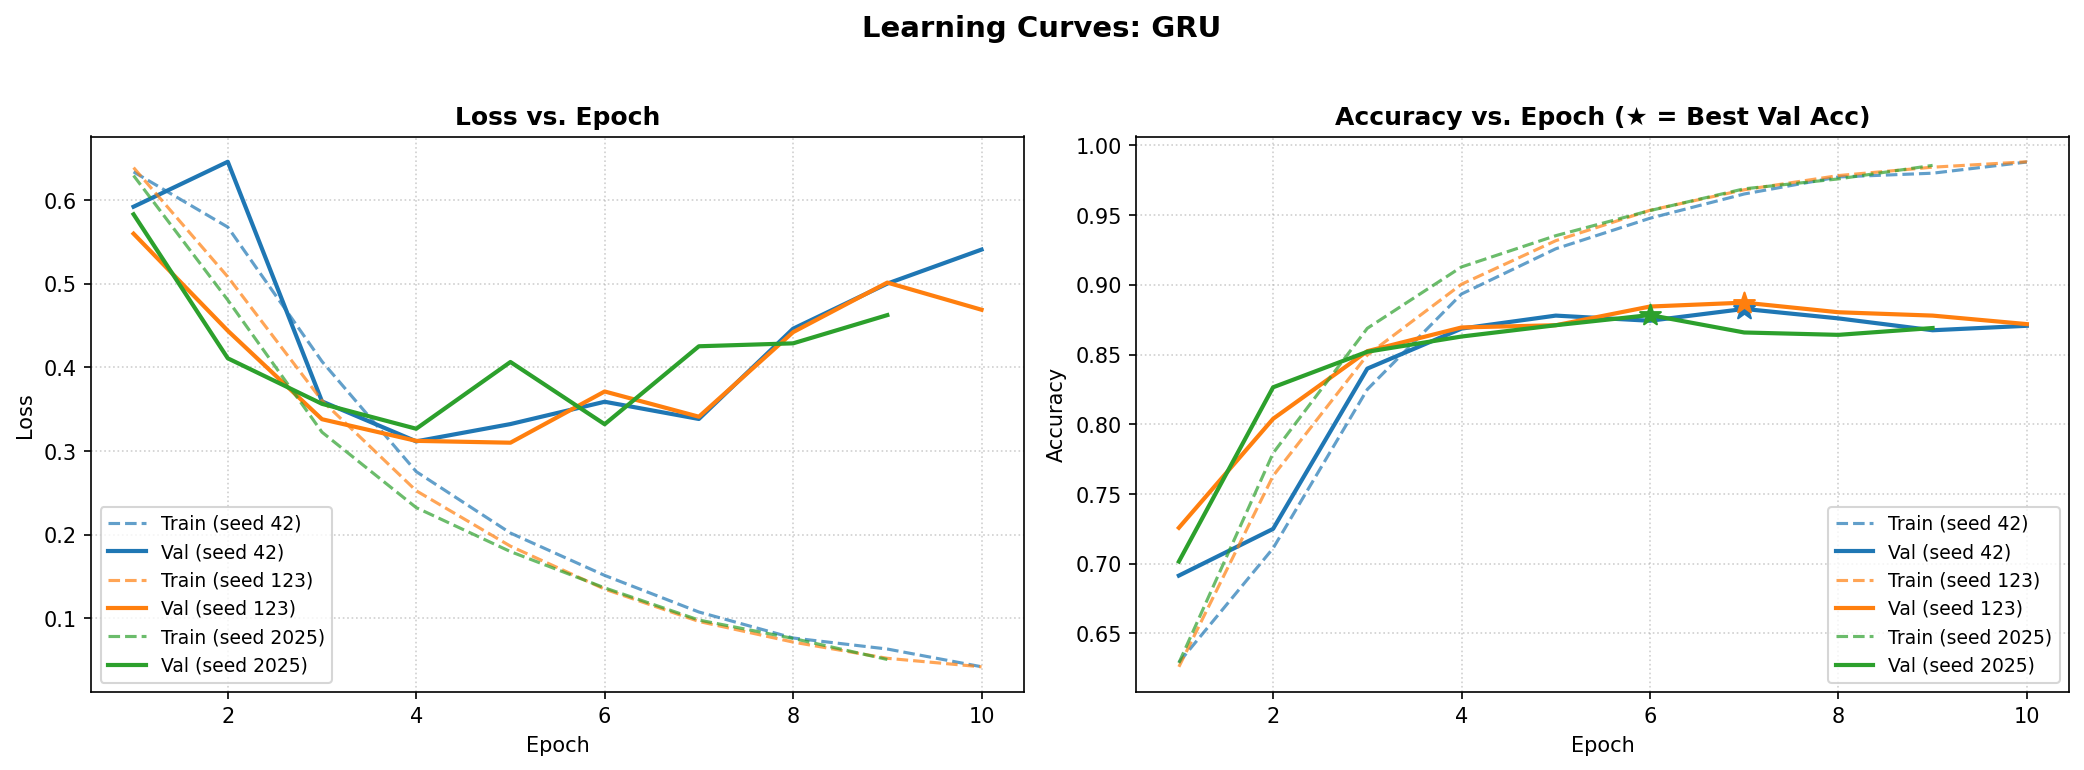

experiments/plots/training/lstm_curves.png


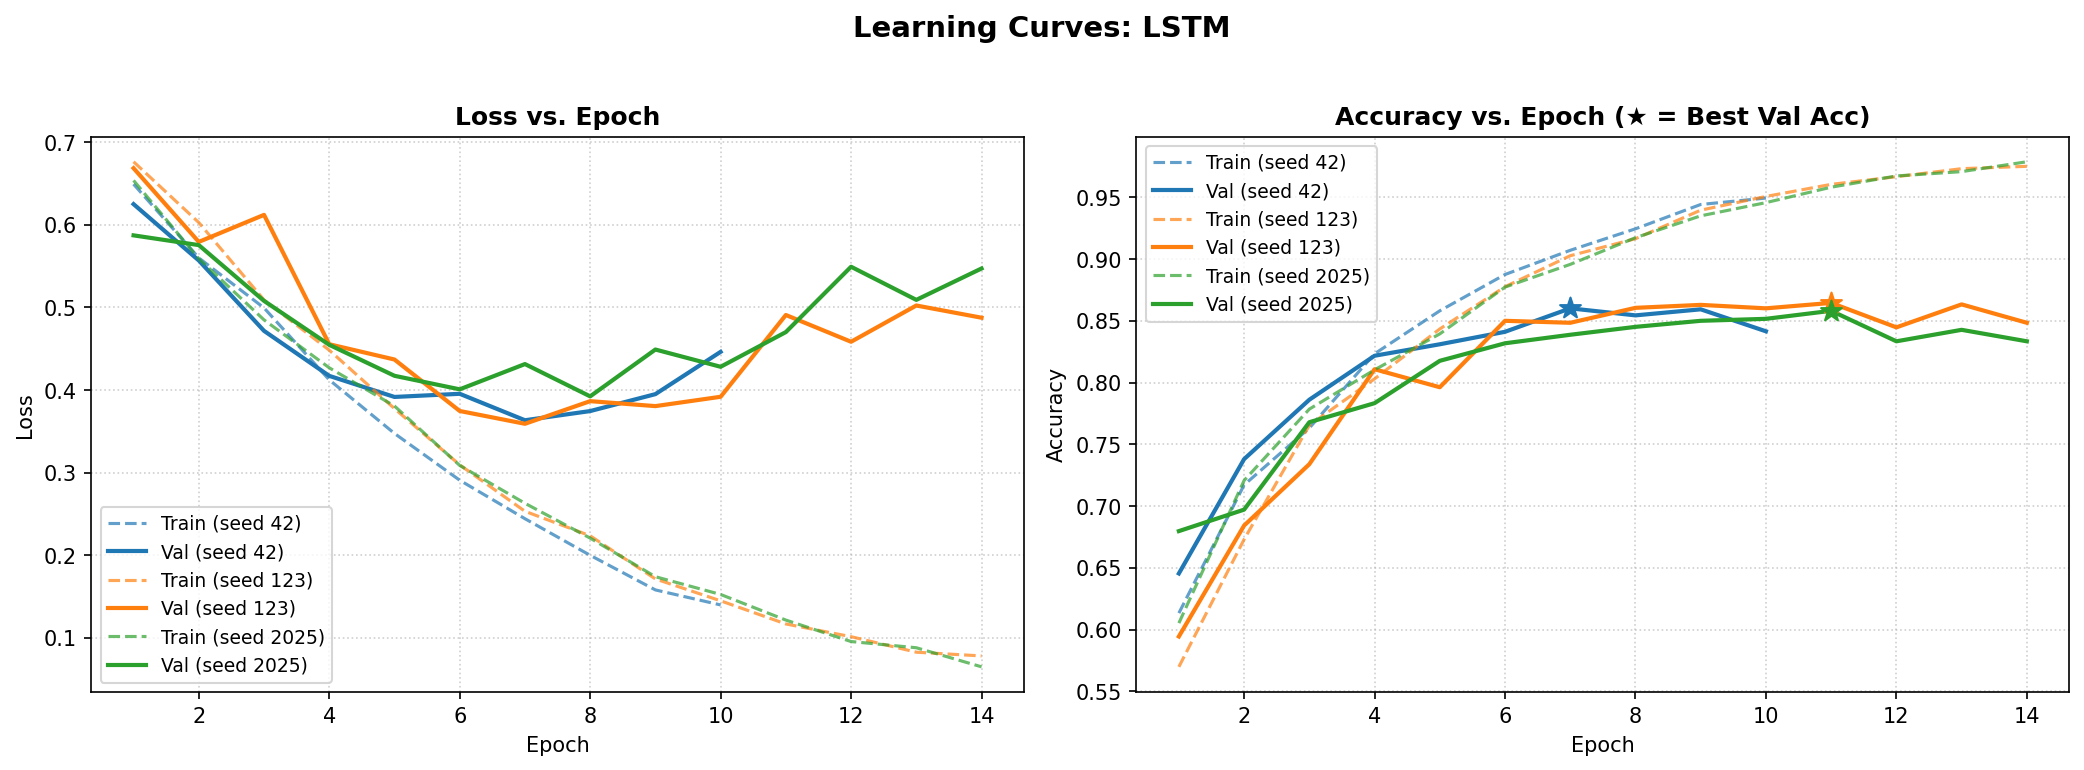

experiments/plots/training/maxlen_200_post_curves.png


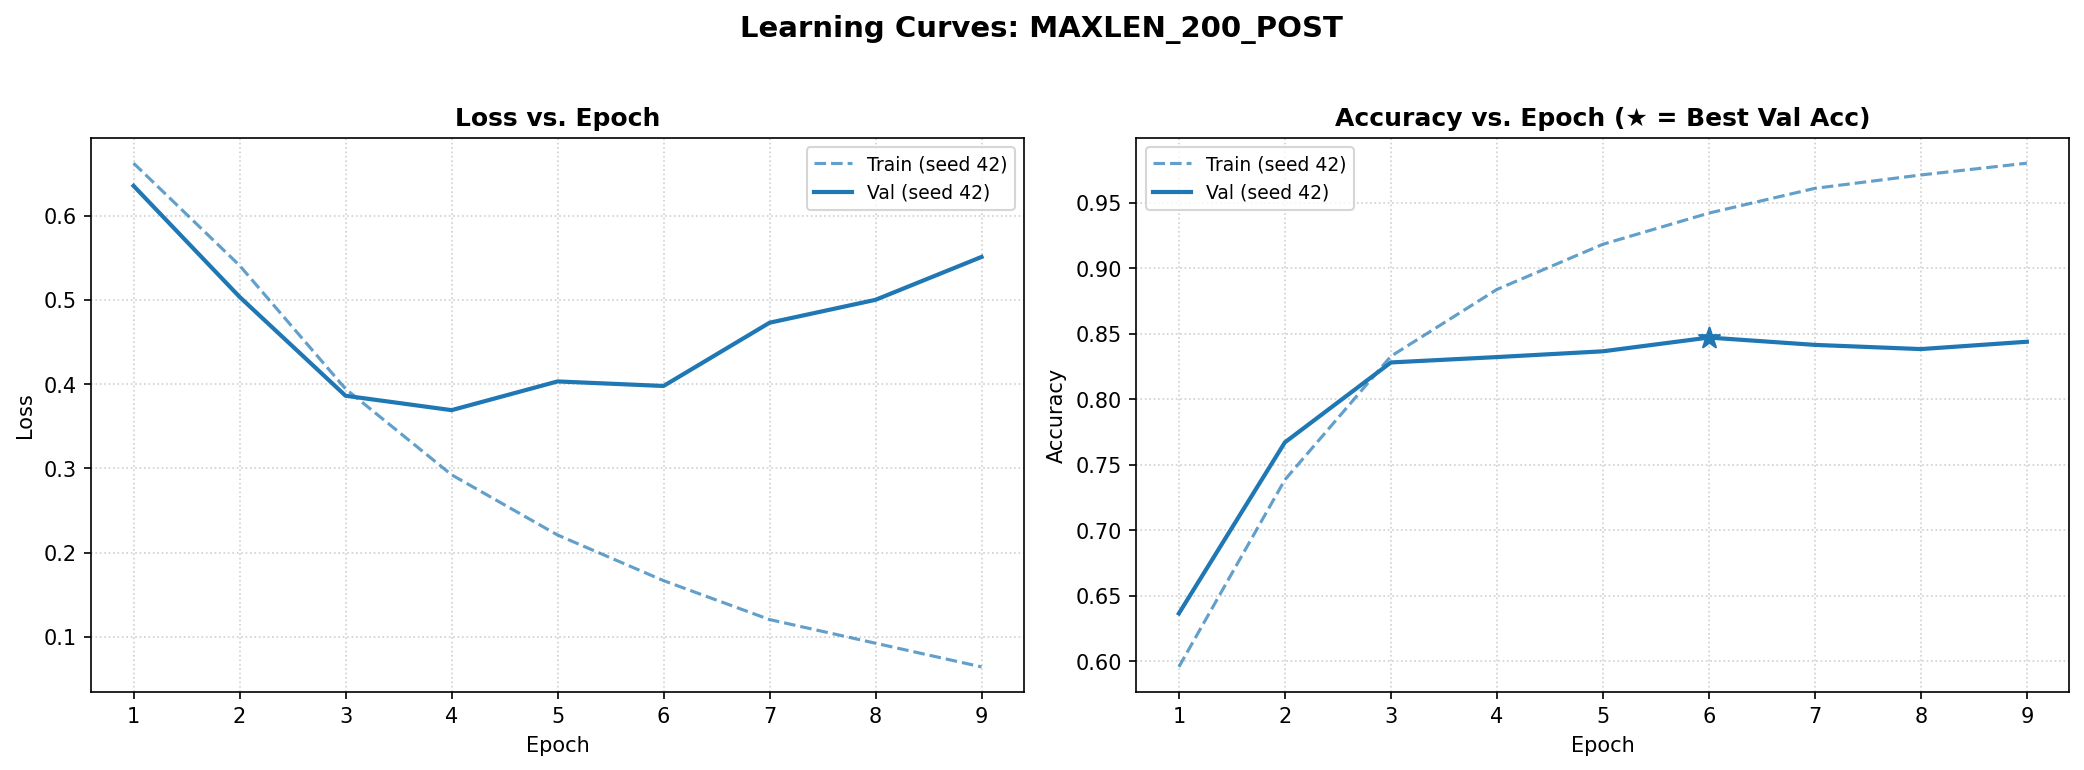

experiments/plots/training/maxlen_400_head_tail_curves.png


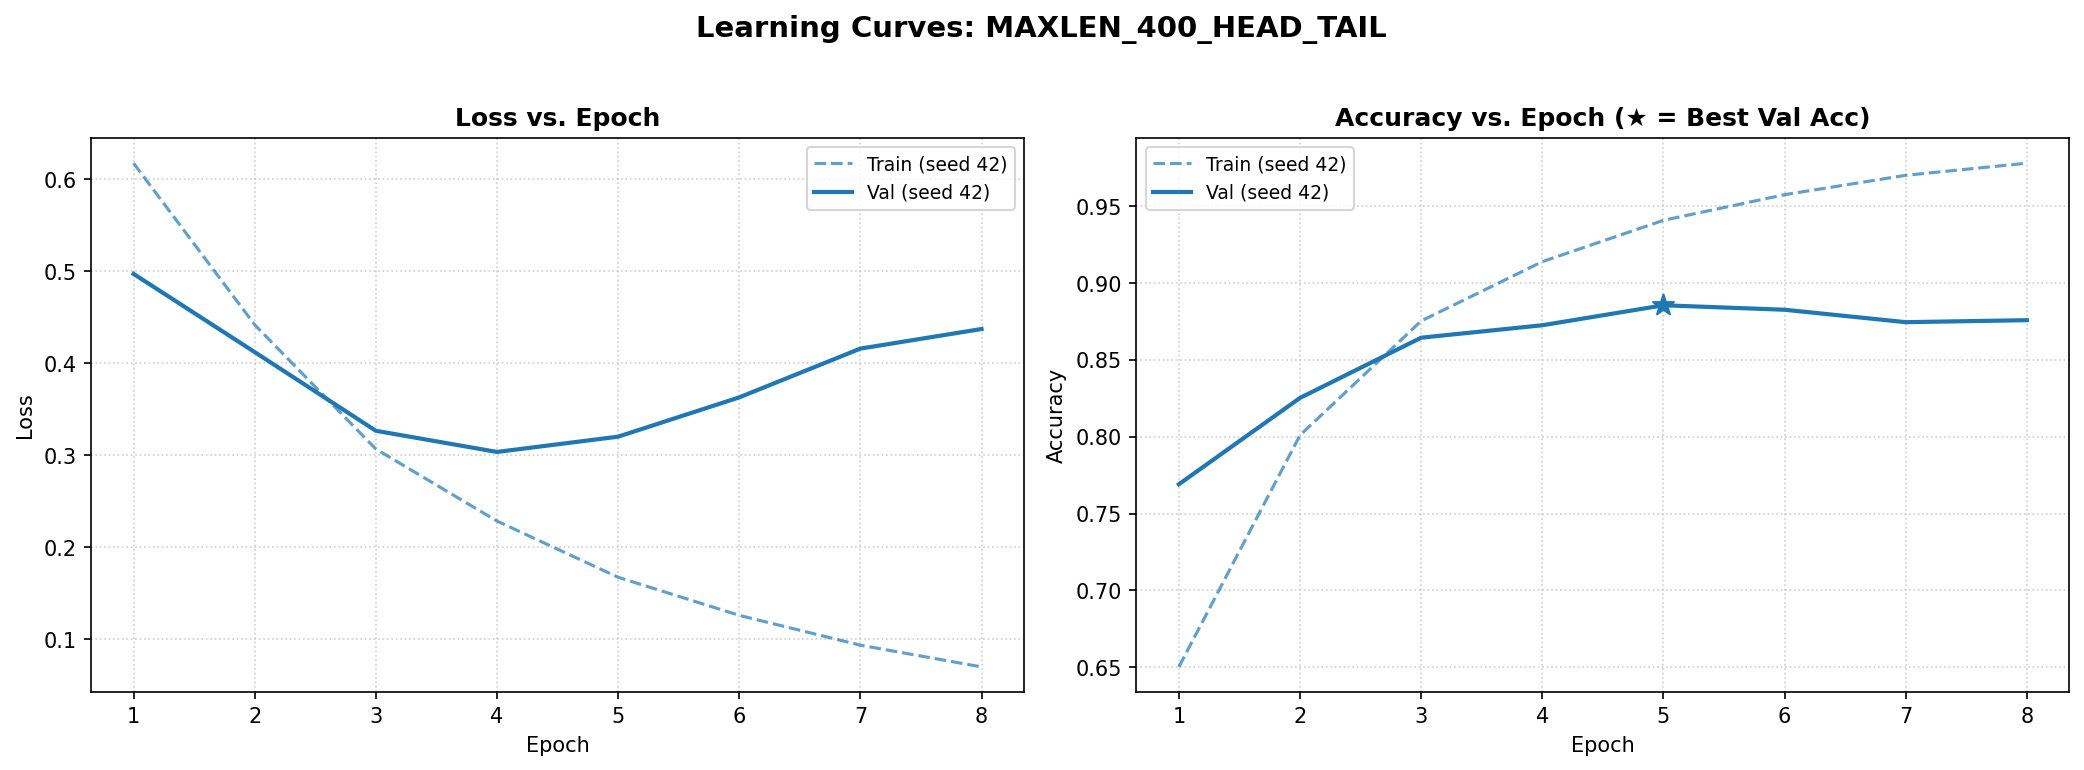

experiments/plots/training/maxlen_400_pre_curves.png


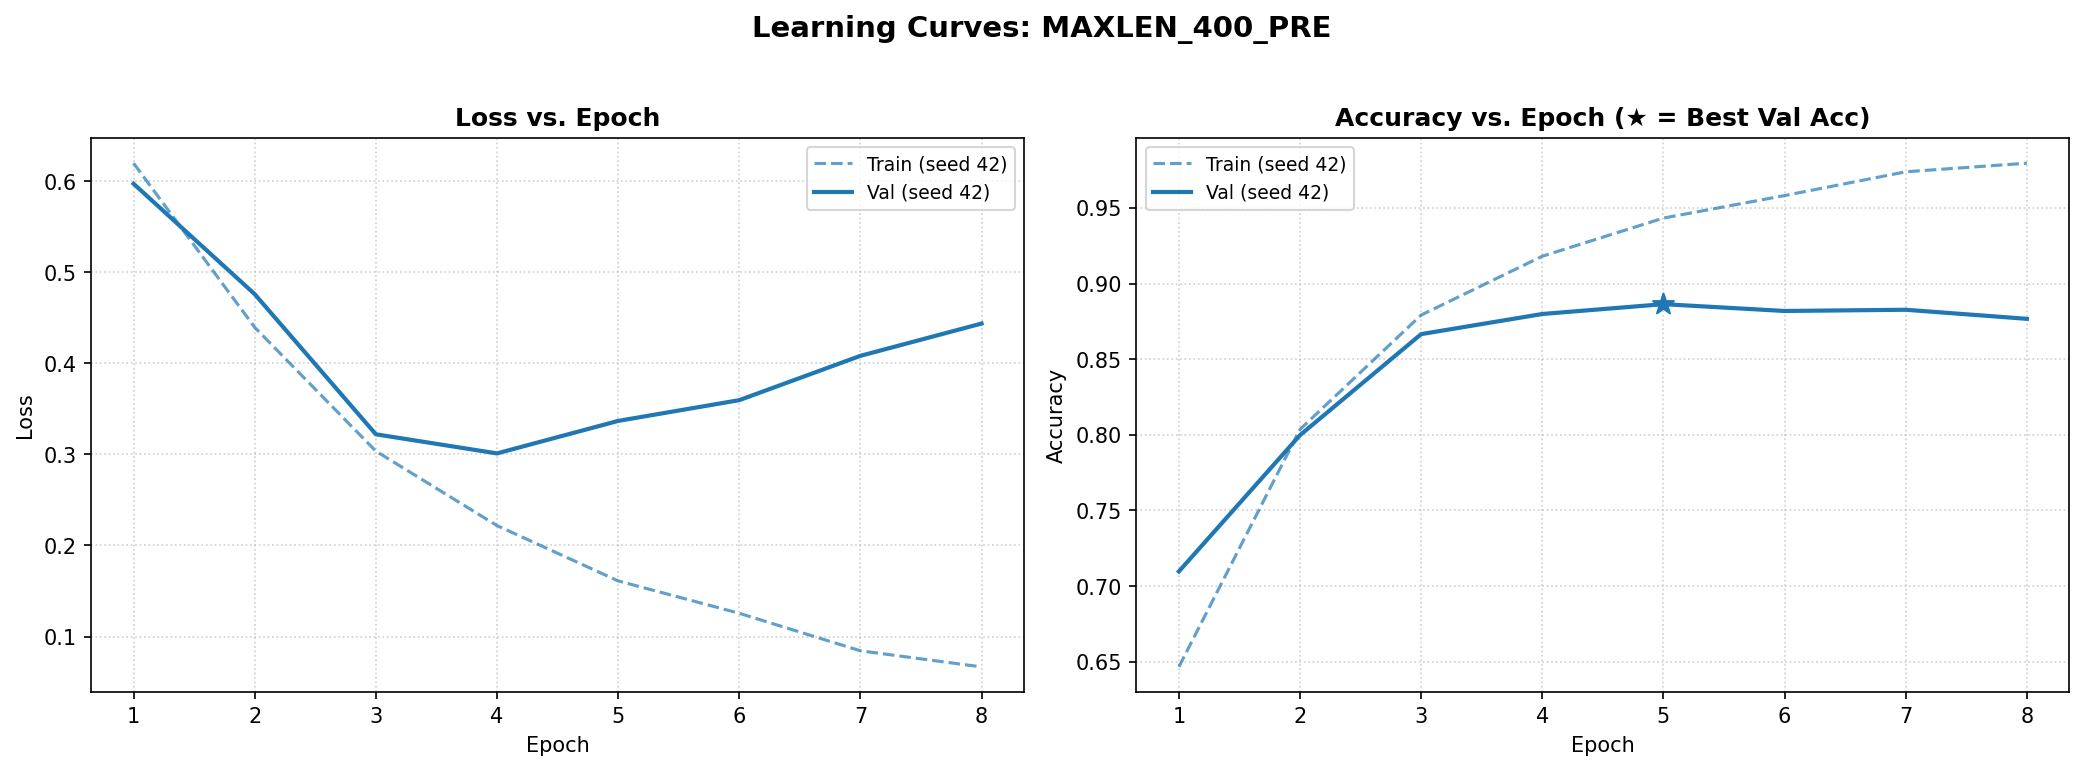

experiments/plots/training/maxlen_600_post_curves.png


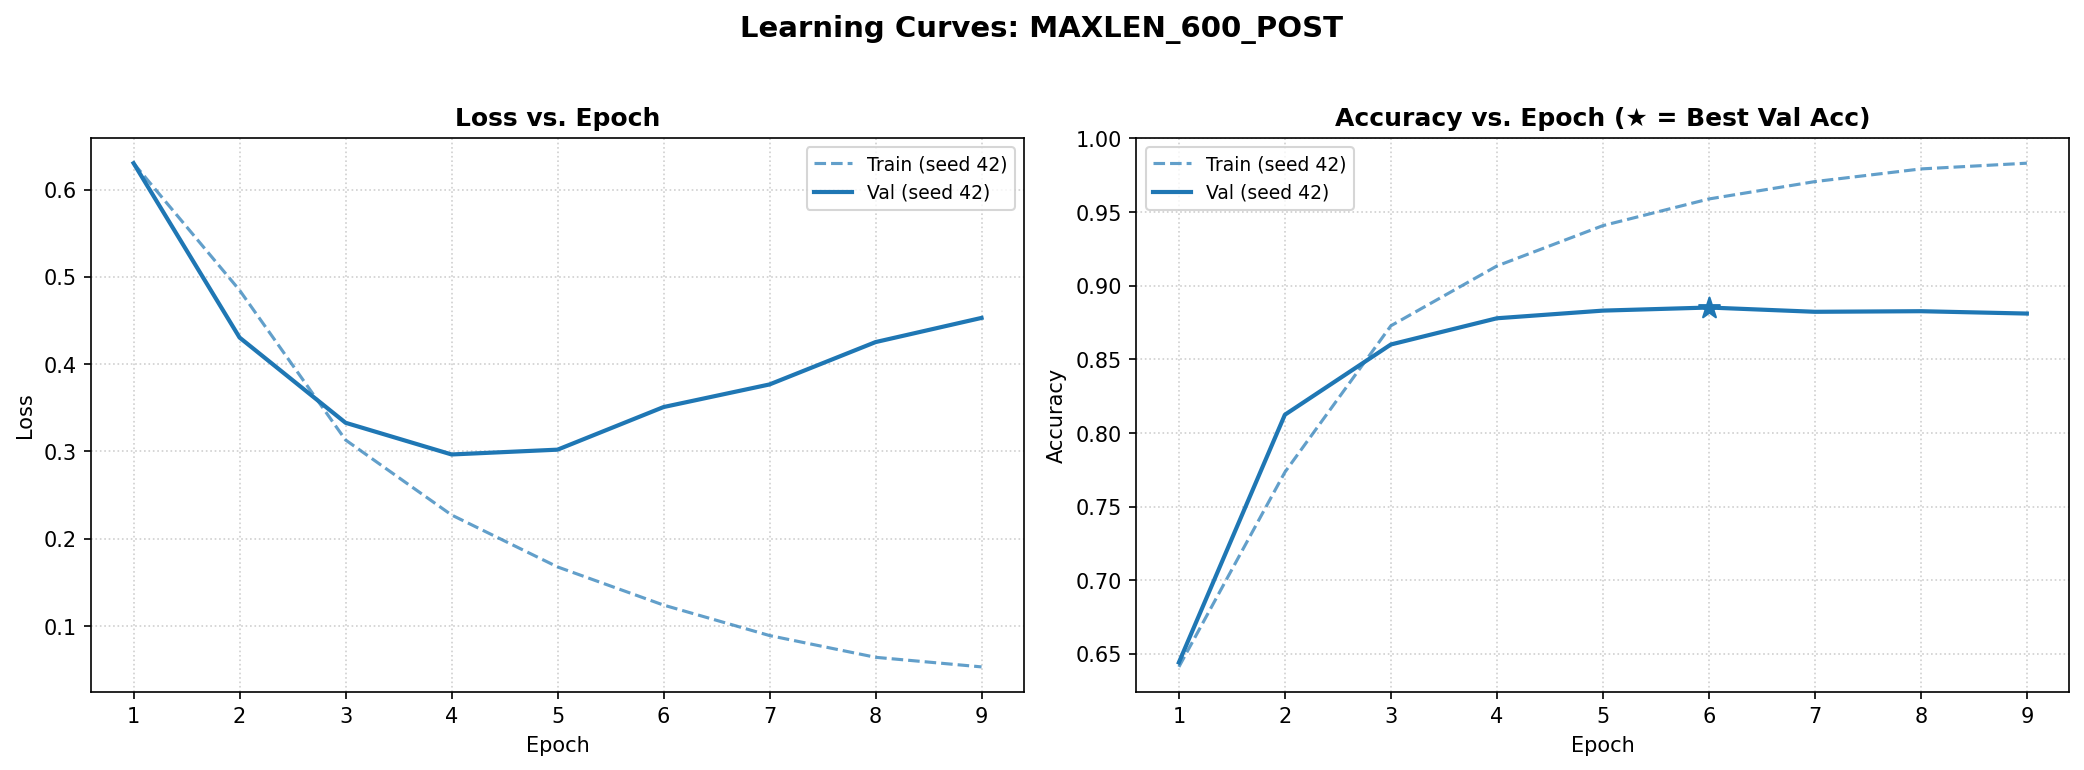

experiments/plots/training/pilot_lstm_ml200_curves.png


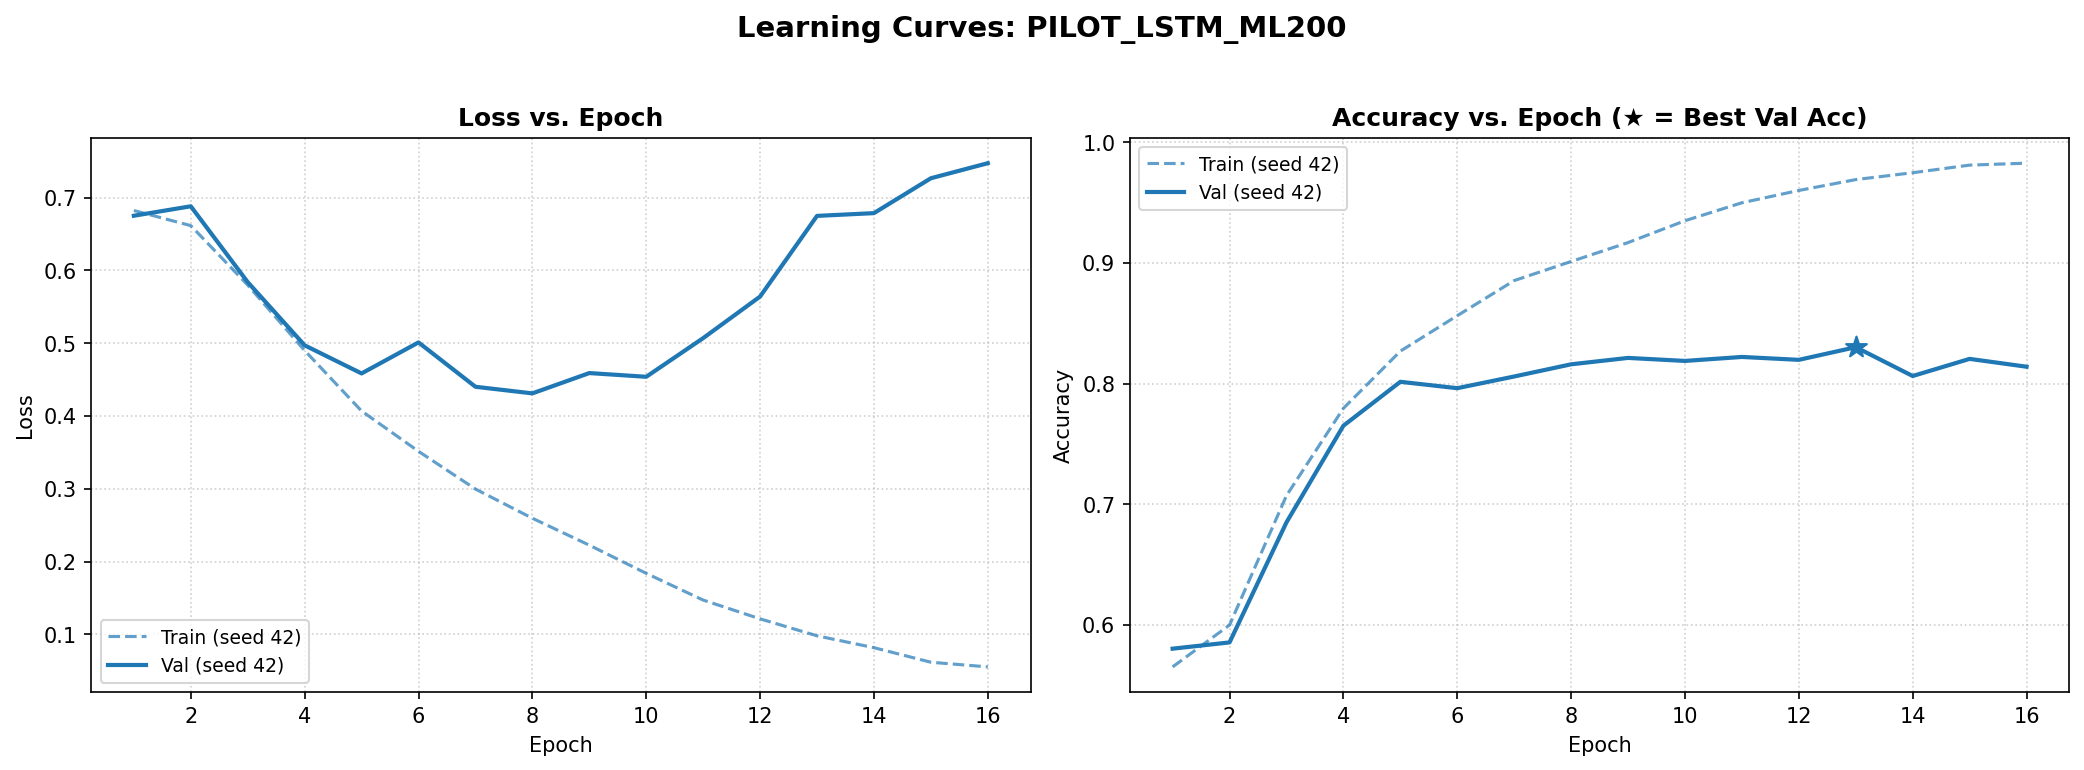

experiments/plots/training/pilot_lstm_ml250_curves.png


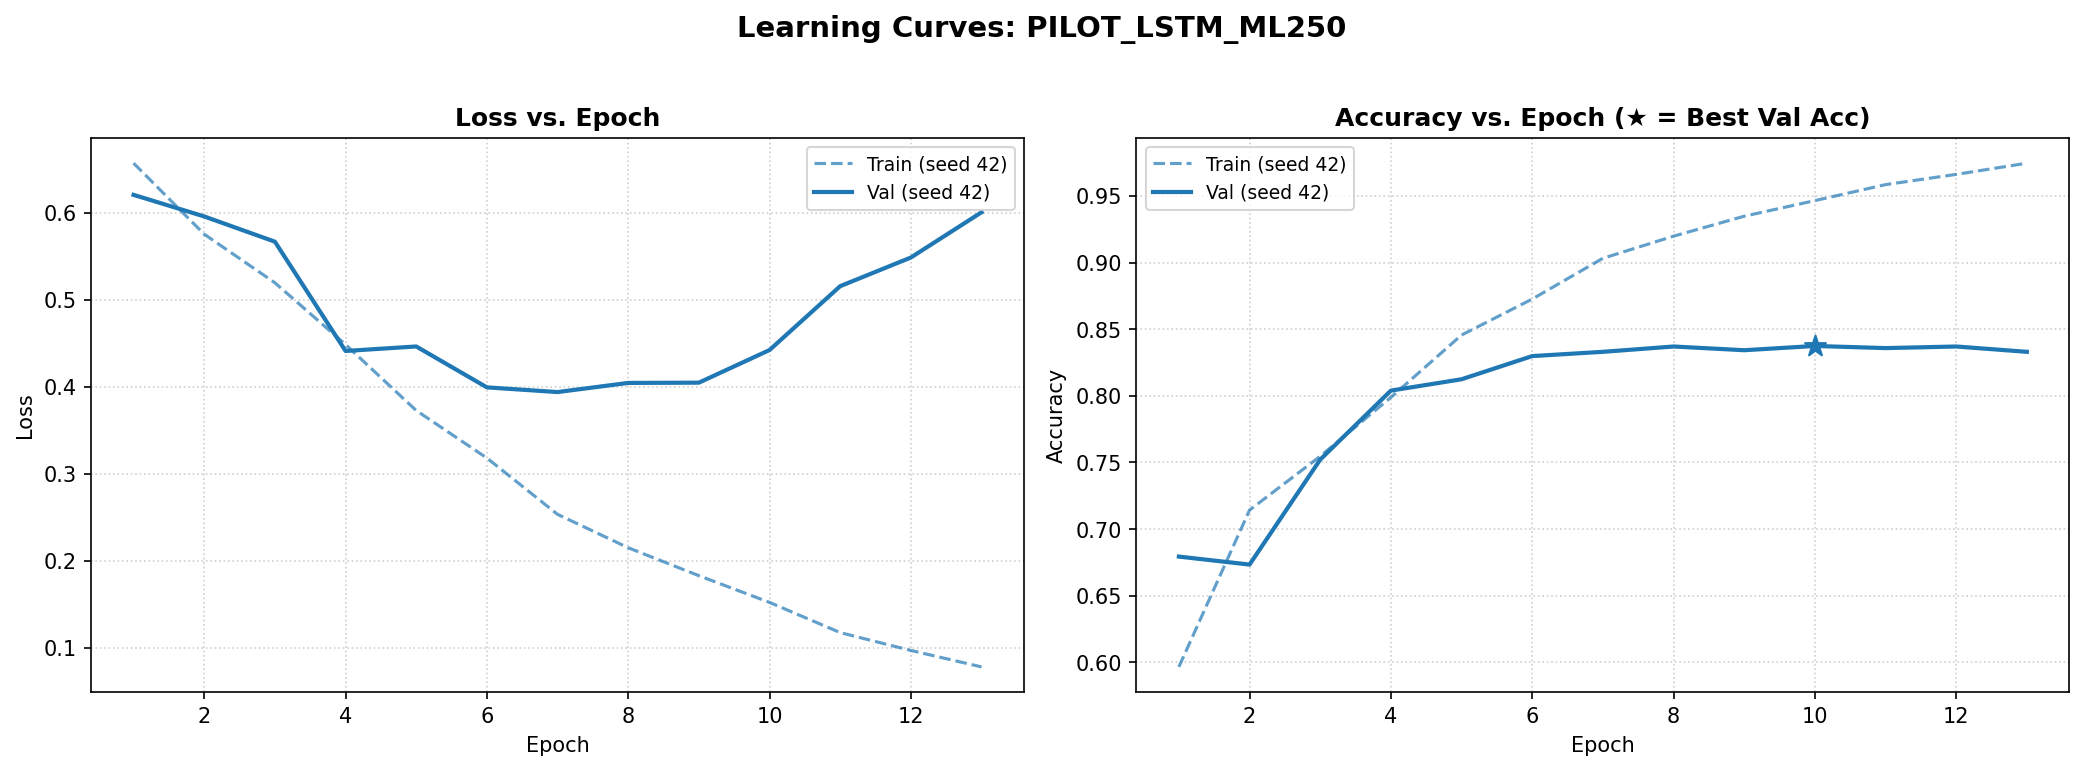

experiments/plots/training/pilot_lstm_ml400_curves.png


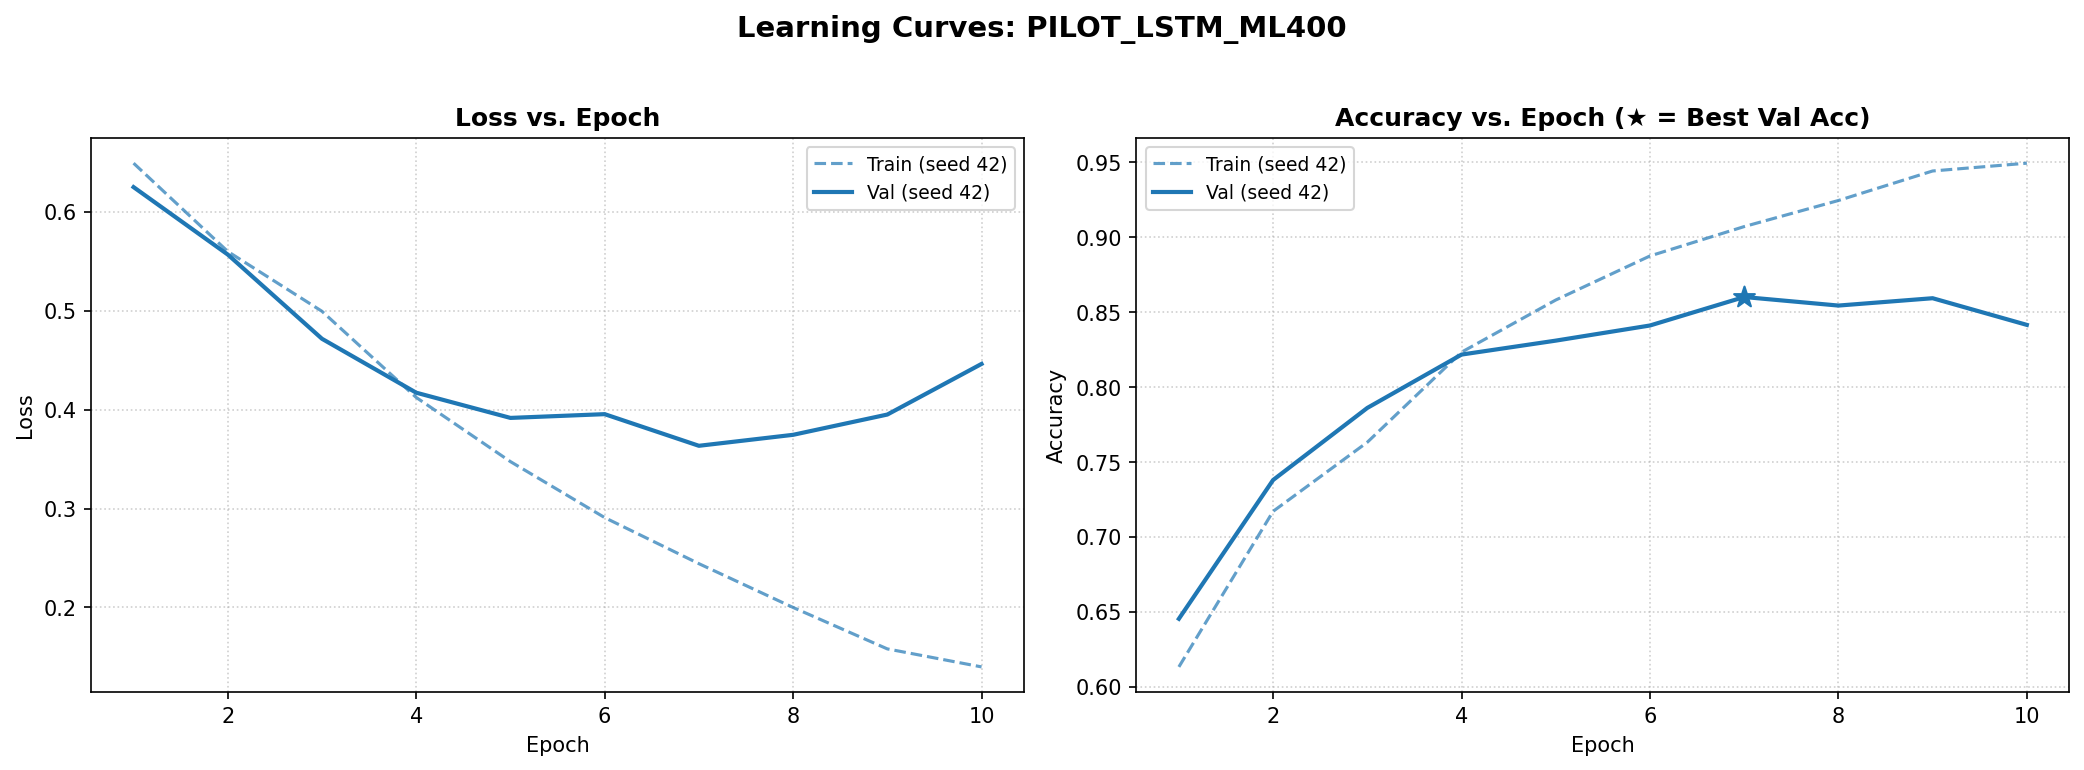

experiments/plots/training/pilot_lstm_ml600_curves.png


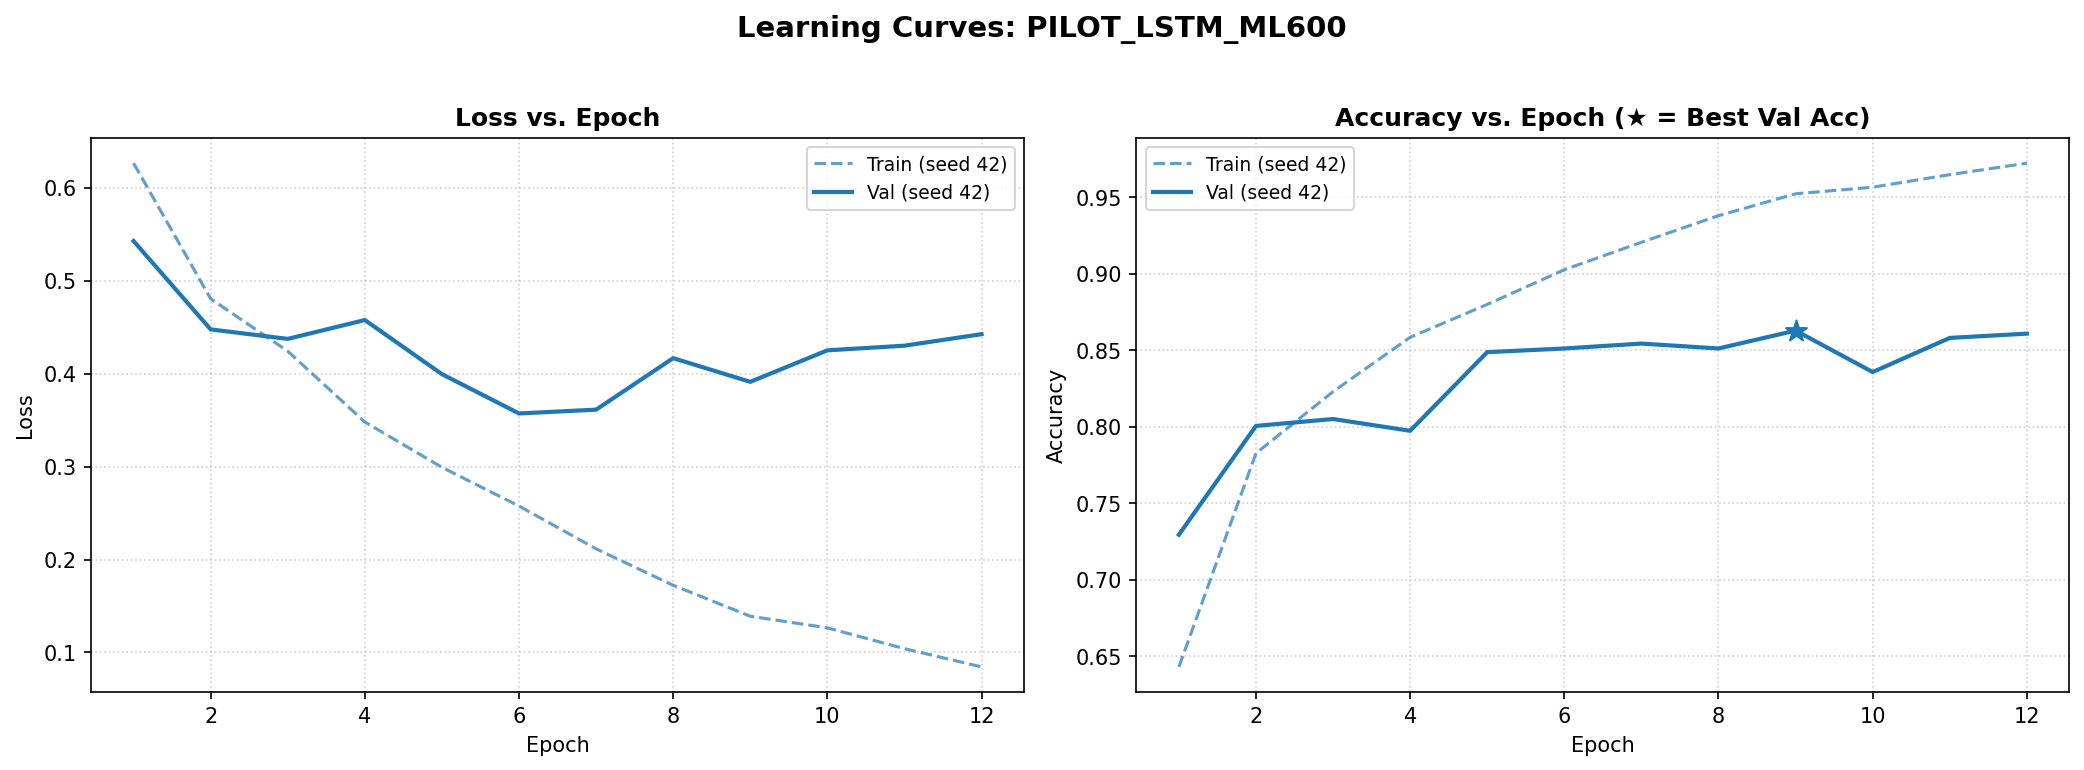

In [10]:
for p in sorted((PLOTS / "training").glob("*.png")) if (PLOTS / "training").exists() else []:
    print(rel(p)); show_img(p, "Đại")

## 6. Đánh giá và so sánh với baseline

Quy trình: chọn cấu hình và checkpoint **chỉ dựa trên val**, sau đó chạy test **một lần**. Bảng so sánh và kiểm định McNemar do Đại tạo (`src/evaluate.py`). Notebook đọc lại các file đó và tự tính lại metric từ file dự đoán để đối chiếu.

In [11]:
for split in ["val", "test"]:
    p = RES / f"comparison_{split}.csv"
    if p.exists():
        display(Markdown(f"**Bảng so sánh — {split}** (`{rel(p)}`)")); display(pd.read_csv(p))
    else:
        waiting(p, "Đại (D7–D8)")

**Bảng so sánh — val** (`experiments/results/comparison_val.csv`)

,model,accuracy,macro_f1,roc_auc,total_params,trainable_params,train_time_s,latency_ms_sample
0,M0a_majority,49.94%,0.3331,0.5000,0,0,—,—
1,M0b_tfidf_lr (C=10),89.85%,0.8985,0.9623,"398,265","398,265",5.5,0.0014
2,bilstm,86.29 ± 0.93%,0.8628 ± 0.0093,0.9348,"2,735,777","2,735,777",194.2,0.394
3,bilstm_attention,88.26 ± 0.58%,0.8825 ± 0.0058,0.9512,"2,768,802","2,768,802",171.2,0.433
4,bilstm_glove_frozen,87.76 ± 0.31%,0.8775 ± 0.0031,0.9468,"2,735,777","235,777",227.4,0.407
5,bilstm_glove_ft,86.70 ± 0.65%,0.8669 ± 0.0066,0.9441,"2,735,777","2,735,777",109.5,0.383
6,gru,88.27 ± 0.45%,0.8827 ± 0.0045,0.9465,"2,588,449","2,588,449",122.8,0.326
7,lstm,86.09 ± 0.33%,0.8609 ± 0.0033,0.9270,"2,617,889","2,617,889",162.7,0.313


**Bảng so sánh — test** (`experiments/results/comparison_test.csv`)

,model,accuracy,macro_f1,roc_auc,total_params,trainable_params,train_time_s,latency_ms_sample
0,M0a_majority,50.00%,0.3333,0.5000,0,0,—,—
1,M0b_tfidf_lr (C=10),89.94%,0.8994,0.9630,"398,265","398,265",5.5,0.3211
2,bilstm,86.53 ± 0.45%,0.8652 ± 0.0045,0.9369,"2,735,777","2,735,777",194.2,0.377
3,bilstm_attention,88.28 ± 0.16%,0.8828 ± 0.0016,0.9527,"2,768,802","2,768,802",171.2,0.411
4,bilstm_glove_frozen,87.87 ± 0.29%,0.8787 ± 0.0028,0.9505,"2,735,777","235,777",227.4,0.379
5,bilstm_glove_ft,86.72 ± 0.34%,0.8670 ± 0.0035,0.9441,"2,735,777","2,735,777",109.5,0.383
6,gru,88.16 ± 0.18%,0.8816 ± 0.0018,0.9499,"2,588,449","2,588,449",122.8,0.315
7,lstm,86.48 ± 0.32%,0.8648 ± 0.0032,0.9321,"2,617,889","2,617,889",162.7,0.31
8,"DistilBERT (tham chiếu Lab 3, không train lại)",93.00–93.40%,—,—,"66,955,010","66,955,010",—,—


Tham chiếu ngoài (không chạy lại): **DistilBERT fine-tune, Lab 3: test acc 0,930–0,934**. Mô hình Transformer có tiền huấn luyện được đưa vào để thấy trần hiệu năng; nó không phải đối thủ cùng hạng với LSTM.

In [12]:
# Chọn mô hình tốt nhất theo val acc từ file dự đoán val (nếu chưa ghi tay BEST_EXP)
val_rows = {}
for exp, name in MODELS.items():
    if pred_file(exp, "val").exists():
        val_rows[exp] = metrics_from_pred(pd.read_csv(pred_file(exp, "val")))
if pred_file("baseline", "val").exists():
    val_rows["baseline"] = metrics_from_pred(pd.read_csv(pred_file("baseline", "val")))
display(pd.DataFrame(val_rows).T.round(4))

cands = {k: v["accuracy"] for k, v in val_rows.items() if k in MODELS}
if not cands:  # repo không lưu predictions_*.csv (33 MB/file) → dùng mean val acc 3 seed trong summary.json
    cands = {k: read_json(RES / k / "summary.json")["best_val_acc"]["mean"]
             for k in MODELS if (RES / k / "summary.json").exists()}
    display(pd.Series(cands, name="val acc (mean 3 seed)").sort_values(ascending=False).round(4).to_frame())
if BEST_EXP is None and cands:
    BEST_EXP = max(cands, key=cands.get)
print("Mô hình tốt nhất (theo val acc):", MODELS.get(BEST_EXP, "⏳ chưa có mô hình nào"))

,n,accuracy,macro_f1,roc_auc
baseline,2473.0,0.8985,0.8985,0.9623


,val acc (mean 3 seed)
gru,0.8827
bilstm_attention,0.8826
bilstm_glove_frozen,0.8776
bilstm_glove_ft,0.8670
bilstm,0.8629
lstm,0.8609


Mô hình tốt nhất (theo val acc): M2 GRU


Không có predictions_test.csv trong repo → dùng số và hình đã lưu của seed 123


,0
split,test
checkpoint,/kaggle/tmp/LSTM_PJ/experiments/checkpoints/gru/seed_123/best.pt
n_removed_train_dups,123
parameters.total,2588449
parameters.trainable,2588449
parameters.embedding_trainable,True
metrics.accuracy,0.8821
metrics.macro_f1,0.8821
metrics.negative_class.precision,0.8795
metrics.negative_class.recall,0.8855


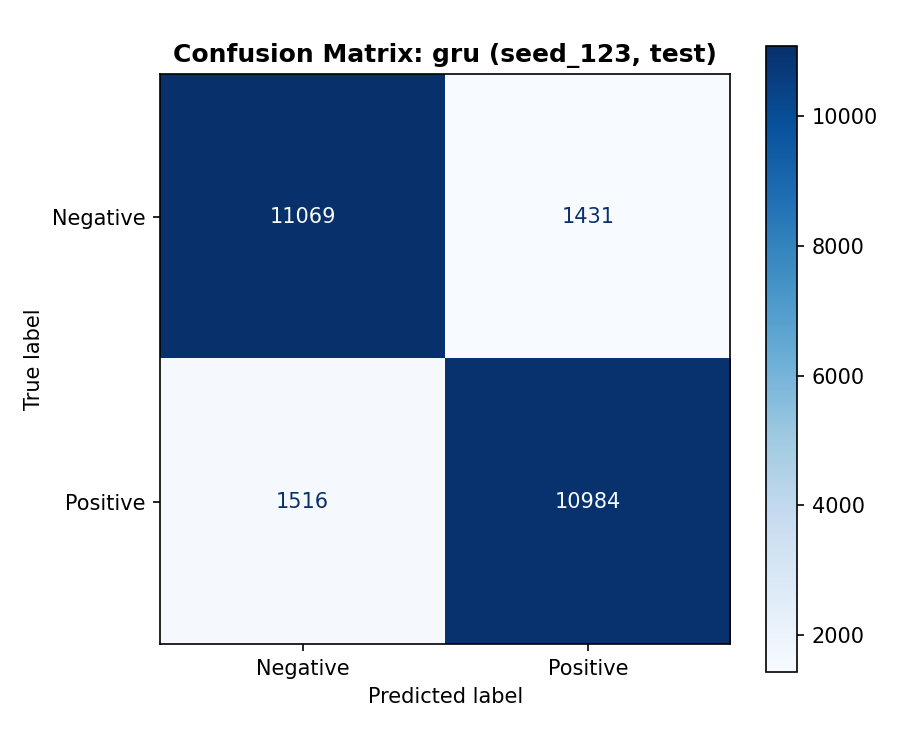

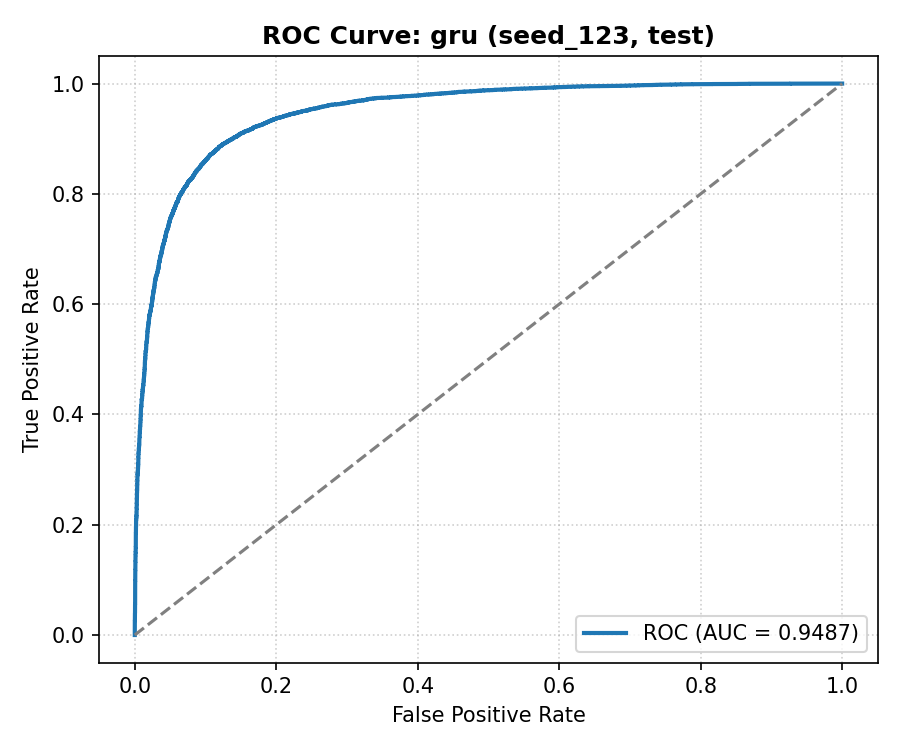

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

if BEST_EXP and pred_file(BEST_EXP, "test").exists():
    test = pd.read_csv(pred_file(BEST_EXP, "test"))
    dup = set((RES / "data_prep" / "test_uids_dup_train.txt").read_text(encoding="utf-8").split())
    res = {"test (25.000)": metrics_from_pred(test),
           f"test bỏ {len(dup)} review trùng train": metrics_from_pred(test[~test["uid"].isin(dup)])}
    display(pd.DataFrame(res).T.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    ConfusionMatrixDisplay.from_predictions(test["label"], test["pred"], display_labels=["neg", "pos"],
                                            ax=axes[0], colorbar=False, values_format="d")
    axes[0].set_title(f"{MODELS[BEST_EXP]} — test")
    RocCurveDisplay.from_predictions(test["label"], test["prob"], ax=axes[1], name=MODELS[BEST_EXP])
    if pred_file("baseline", "test").exists():
        b = pd.read_csv(pred_file("baseline", "test"))
        RocCurveDisplay.from_predictions(b["label"], b["prob"], ax=axes[1], name="M0b TF-IDF + LR")
    plt.tight_layout(); plt.show()
elif BEST_EXP:
    s = best_seed(BEST_EXP)
    tm = RES / BEST_EXP / f"seed_{s}" / "test_metrics.json"
    print(f"Không có predictions_test.csv trong repo → dùng số và hình đã lưu của seed {s}")
    if tm.exists():
        display(pd.json_normalize(read_json(tm)).T)
    for kind in ["cm", "roc"]:
        show_img(PLOTS / "eval" / f"{BEST_EXP}_seed_{s}_test_{kind}.png", "D8", width=480)
else:
    waiting(RES / "<exp>" / "predictions_test.csv", "Đại (D8)")

In [14]:
p = RES / "mcnemar.json"
if p.exists():
    display(pd.json_normalize(read_json(p)).T)
else:
    waiting(p, "Đại (D8)")

,0
model_a,gru
model_b,M0b_TFIDF_LR
better_model,M0b_TFIDF_LR
statistic,71.6407
p_value,0.0
exact_p_value,0.0
chi2_p_value,0.0
significant_p05,True
significant_p01,True
interpretation,M0b_TFIDF_LR tốt hơn gru có ý nghĩa thống kê (p = 0.000000 < 0.05; đúng riêng 1519 so với 1086 mẫu)


### Chốt `max_len` (pilot D5) và mở rộng A (D7)

Theo plan, `max_len` được chốt ở bước pilot D5 **trước** 18 lần chạy chính: LSTM M1, seed 42, so sánh trên val. Quy tắc ghi trước khi chạy: lấy val acc cao nhất; nếu chênh < 0,5 điểm thì lấy giá trị nhỏ hơn (chạy nhanh hơn). Cả 6 mô hình chính dùng giá trị đã chốt, cắt đuôi (`post`). D7 thử thêm cách cắt và các mức khác trên mô hình tốt nhất (1 seed).

In [15]:
p, d = RES / "pilot_maxlen.csv", RES / "pilot_decision.json"
if p.exists():
    display(Markdown("**Pilot D5**")); display(pd.read_csv(p))
    if d.exists():
        dd = read_json(d)
        print(f"Chốt max_len = {dd['chosen_max_len']} · quy tắc: {dd['rule']} · best epoch < trần {dd['max_epochs']}: {dd['epoch_cap_ok']}")
else:
    waiting(p, "D5")
p = RES / "maxlen_comparison.csv"
display(Markdown("**Mở rộng A (D7)**"))
display(pd.read_csv(p)) if p.exists() else waiting(p, "D7")

**Pilot D5**

,max_len,best_val_acc,best_epoch,train_seconds
0,200,0.8302,13,162.2
1,250,0.8374,10,138.7
2,400,0.8601,7,128.5
3,600,0.8629,9,191.5


Chốt max_len = 400 · quy tắc: val acc cao nhất; chênh < 0.5 điểm thì chọn max_len nhỏ hơn · best epoch < trần 20: True


**Mở rộng A (D7)**

,variant,base_model,max_len,truncation,pct_train_truncated,val_accuracy,val_macro_f1,val_roc_auc,train_seconds,latency_ms_per_sample
0,maxlen_200_post,gru,200,post,52.32,0.8471,0.8470,0.9263,88.8,0.264
1,maxlen_600_post,gru,600,post,7.88,0.8852,0.8852,0.9482,145.9,0.378
2,maxlen_400_pre,gru,400,pre,18.73,0.8864,0.8864,0.9490,103.1,0.318
3,maxlen_400_head_tail,gru,400,head_tail,18.73,0.8856,0.8855,0.9510,101.5,0.322


**Nhận xét** (chi tiết từng thí nghiệm: `docs/experiments/EXP_02`–`EXP_07`):
- **Baseline vẫn thắng.** TF-IDF + LR 89,94% test, hơn GRU (mô hình chọn theo val) 1,8 điểm. McNemar: baseline đúng riêng 1.519 review, GRU đúng riêng 1.086, p < 0,001 → khác biệt có ý nghĩa thống kê. TF-IDF đọc toàn bộ review và tận dụng tốt các từ khoá cảm xúc; RNN chỉ thấy 400 token và phải tự học nghĩa từ với 22 nghìn review.
- **GRU hơn LSTM khoảng 2 điểm** (88,16% so với 86,48%) dù ít tham số hơn và train nhanh hơn 25%; ổn định hơn qua 3 seed.
- **BiLSTM không giúp:** +0,05 điểm test so với LSTM, nhỏ hơn độ lệch giữa các seed.
- **GloVe đóng băng +1,3 điểm** so với embedding ngẫu nhiên và ổn định nhất; **fine-tune GloVe mất gần hết lợi ích** vì overfit sau 3–4 epoch.
- **Attention pooling +1,75 điểm** so với hidden cuối, ROC-AUC cao nhất (0,9527) — ngang GRU. Nhóm giữ GRU vì quy tắc chọn theo mean val acc (88,27% so với 88,26%), không đổi sau khi xem test.
- **`max_len` ảnh hưởng lớn nhất:** 250 → 400 làm mọi mô hình tăng 1,6–2,2 điểm test; 600 gần như không thêm; cách cắt (`post` / `pre` / `head_tail`) chênh trong mức nhiễu.
- **Mục tiêu đăng ký:** M1 (LSTM ≥ 85%) và M2 (mô hình tốt nhất ≥ 88%, macro-F1 ≥ 0,88) đều đạt.

## 7. Phân tích lỗi

Phân tích trên test chỉ để **mô tả**, không quay lại tinh chỉnh mô hình. Có 7 nhóm tình huống (`docs/phases/EVAL.md`):

1. Độ dài: < 100, 100–300, 300–600, > 600 từ (cắt ngắn có làm mất câu kết luận không).
2. Phủ định.
3. Khen chê lẫn lộn, đổi giọng ở cuối.
4. Mỉa mai, châm biếm.
5. Điểm sát ngưỡng (4, 7) so với điểm cực trị (1, 10).
6. Nhiều từ OOV hoặc từ hiếm.
7. 30 câu tự viết (`data/sample/handwritten_30.csv`).

Bảng đầy đủ và ví dụ sai kèm giải thích do `src/eval/error_analysis.py` (T2) tạo, lưu ở `experiments/results/error_analysis/`.

In [16]:
EA = RES / "error_analysis"
files = sorted(EA.glob("*.csv")) if EA.exists() else []
for p in files:
    display(Markdown(f"**`{rel(p)}`**")); display(pd.read_csv(p).head(15))
if not files:
    waiting(EA, "Thư (T2), sau khi Đại có file dự đoán test")

**`experiments/results/error_analysis/by_group.csv`**

,group,subgroup,n,share,acc_model,n_errors_model,acc_baseline,delta_model_minus_baseline
0,length,<100,2290,0.0916,0.8891,254,0.9083,-0.0192
1,length,100–300,15529,0.6212,0.8927,1667,0.9010,-0.0084
2,length,300–600,5342,0.2137,0.8740,673,0.8912,-0.0172
3,length,>600,1839,0.0736,0.8080,353,0.8989,-0.0908
4,truncated,False,20600,0.8240,0.8929,2206,0.9009,-0.0080
5,truncated,True,4400,0.1760,0.8316,741,0.8925,-0.0609
6,negation,0–2,11207,0.4483,0.8928,1201,0.9053,-0.0125
7,negation,3–5,8440,0.3376,0.8832,986,0.8941,-0.0109
8,negation,6+,5353,0.2141,0.8580,760,0.8956,-0.0375
9,contrast_end,False,13205,0.5282,0.8956,1379,0.9111,-0.0155


**`experiments/results/error_analysis/error_examples.csv`**

,case,uid,label,pred,prob,rating,n_tokens,was_truncated,n_negation,contrast_end,sarcasm_candidate,text,explanation
0,length=>600,test_neg_8319,0,1,0.998383,4,871,True,11,True,False,The Brave One is about a New York radio show host named Erica Bain (Jodie Foster). Her life is a dream living in the...,"[cắt mất kết luận] Kết luận chê ('rotten by the end', 1.5/4) nằm cuối review 871 token, bị cắt ở 400; phần đầu khen ..."
1,length=>600,test_neg_9701,0,1,0.997830,4,1028,True,13,True,False,"Let me begin by saying that I adore the book and loved the A&E miniseries. I was hoping to love this film, and I was...","[khen chê lẫn lộn] Phần đầu đã chê rõ ('this film scarcely resembles the original book'), nhưng ngay trước điểm cắt ..."
2,length=>600,test_pos_10357,1,0,0.002834,7,968,True,12,True,True,Brain of Blood starts as Abdul Amir (Reed Hadley) the leader of a country called Kahlid is close to death because of...,"[khen kiểu dở mà vui] Lời khen đã có trong 400 token đầu ('terrific fun in a so bad it's good sort of way', token ~2..."
3,length=>600,test_neg_6372,0,1,0.996612,1,770,True,9,True,False,I have been collecting Iron Man comics since the early 70s and always enjoyed the character who is far far from the ...,"[khen chê lẫn lộn, không chắc] Đã chê rõ trước token 400 ('Boy was I wrong!' token 77, 'Bad CGI' token 192), xen khe..."
4,length=>600,test_neg_11090,0,1,0.995266,4,859,True,6,True,False,Julie Delpy stars in this horrific film about a sadistic relationship between a father and a daughter in France of t...,[khen chê lẫn lộn] 400 token đầu chủ yếu tóm tắt cốt truyện bạo lực ('sadistic relationship'); cả câu chê 'the movie...
5,length=>600,test_pos_4741,1,0,0.005936,10,669,True,9,False,False,"After watching ""Waco: The Rules of Engagement"" I was just sitting in disbelief of what I was witness to. A big cover...","[nhầm chủ đề với đánh giá] Phim tài liệu về Waco; từ tiêu cực (massacre, cover up, kill) mô tả sự kiện, không phải c..."
6,length=>600,test_neg_2621,0,1,0.993832,2,993,True,16,False,False,Retro Puppet Master starts in Kolewige during 1944 where puppet master Andre Toulon (Guy Rolfe) & his living puppets...,"[đổi đối tượng] Lời chê đã có trong 400 token đầu ('it's the worse of the series so far', token 275); lời khen thuộc..."
7,length=>600,test_neg_2716,0,1,0.993539,3,972,True,10,True,False,"Tacky, but mildly entertaining early 90's soft core comedy features Xena (Sarah Bellemo), Luna (Tamara Landry), and ...","[khen chê lẫn lộn] Giọng lửng lơ ('Tacky, but mildly entertaining'), không ngược hẳn điểm 3; 'mildly recommending' n..."
8,length=>600,test_pos_754,1,0,0.006588,9,1962,True,17,True,False,"If anyone ever assembles a compendium on modern American horror that is truly worth it's salt, there will *have* to ...","[cắt mất kết luận] Điểm '***1/2 out of ****' bị cắt, nhưng phần đầu đã khen ('I am impressed by the complete economy..."
9,length=>600,test_neg_12185,0,1,0.993411,4,807,True,4,False,False,"This was the next to last film appearance by Jill Ireland, who died of cancer in 1990 after four decades as a well-k...","[cắt mất kết luận] 'late Cannon slop work' và '** out of 4' nằm sau token 400; phần đầu chỉ có một câu chê, 'careles..."


**`experiments/results/error_analysis/handwritten_30_predictions.csv`**

,text,label,case_type,prob,pred,correct,prob_baseline,pred_baseline,correct_baseline
0,"Every scene feels carefully considered, and the lead actress delivers an emotional performance that made the entire ...",1,positive,0.9634,1,True,0.7116,1,True
1,I loved how the director balanced humor and tension without making either feel forced. The final sequence was especi...,1,positive,0.9958,1,True,0.8334,1,True
2,"The writing is sharp, the soundtrack fits every moment, and the supporting cast brings surprising depth to even the ...",1,positive,0.8616,1,True,0.6280,1,True
3,"From the opening scene to the closing credits, the film kept me completely absorbed. I would happily watch it again.",1,positive,0.2475,0,False,0.7593,1,True
4,Beautiful cinematography and genuinely thoughtful storytelling make this film feel fresh. Nothing about the experien...,1,positive,0.2494,0,False,0.7265,1,True
5,"The plot is painfully predictable, and the characters behave in ways that make absolutely no sense. I struggled to f...",0,negative,0.0073,0,True,0.0427,0,True
6,"Flat dialogue, awkward editing, and lifeless performances turn what could have been an interesting story into a frus...",0,negative,0.0466,0,True,0.0372,0,True
7,"I kept waiting for something meaningful to happen, but the film offered nothing beyond repetitive conversations and ...",0,negative,0.0027,0,True,0.0409,0,True
8,"The soundtrack constantly overwhelms the dialogue, while the poorly developed characters make it impossible to care ...",0,negative,0.1952,0,True,0.0771,0,True
9,"Even the supposedly emotional moments feel artificial. The story lacks direction, and the ending only makes its prob...",0,negative,0.0032,0,True,0.1859,0,True


**`experiments/results/error_analysis/manual_label_50.csv`**

,uid,label,pred,prob,rating,n_tokens,was_truncated,contrast_end,sarcasm_candidate,text,manual_type,note
0,test_pos_3171,1,0,0.169520,8,241,False,True,False,The Tempest has been interpreted in many different ways ranging from more or less traditional views as dealing with ...,mixed,"Khen diễn viên phụ, chê Prospero; kết 'interesting but not quite the success' nghe như chê nhưng chấm 8."
1,test_neg_5480,0,1,0.642275,1,538,True,True,False,"This game was terrible. I think they worked too hard on the visuals and didn't do much with the gameplay, which is t...",target_shift,"Review game, không phải phim; chê ngay câu đầu ('This game was terrible') nhưng khen game khác ('THAT'S a game that ..."
2,test_pos_8681,1,0,0.129114,7,198,False,True,False,Track Listing: 1. Spiderbait - Outta My Head 2. Lash - Take Me Away 3.Lavaland - Everwonder 4. Machine Gun Fellatio ...,other,"Gần như toàn danh sách bài hát (OOV, tên riêng); lời khen 'Loved this movie' chỉ ở câu cuối."
3,test_neg_2660,0,1,0.943502,3,471,True,True,False,Nothing could be more appealing than the idea of a good love story featuring Kristin Scott Thomas and Harrison Ford....,sarcasm,"'what could possibly be more lovely? Well, this is not that movie', 'lovely Kristin' dùng mỉa mai."
4,test_neg_8330,0,1,0.992706,3,272,False,True,False,"Well, This was my first IMAX experience so I was pretty blown away about that, primarily; although with hindsight, I...",target_shift,"Khen trải nghiệm IMAX ('I loved the IMAX experience'), chê bộ phim ('dearly wish a different film had been on')."
5,test_neg_11630,0,1,0.577956,4,964,True,True,False,Mickey Rourke is enjoying a renaissance at the moment... and fair play to him. I always liked his image and his acti...,negation,"Đã chê qua phủ định trong 400 token đầu ('this whole thing just doesn't make sense' token ~79, 'A wealth of things a..."
6,test_pos_4006,1,0,0.041056,7,359,False,True,False,"I cannot hate on the show. When the old (and better) tech TV had to hit the bricks, the channel was reformatted and ...",negation,"'I cannot hate on the show', 'aren't as geek as I'd like' — phủ định bọc lời khen; kết khen."
7,test_neg_3569,0,1,0.693094,3,705,True,True,False,"Why spend a moment slogging through this awkward and self-conscious movie? Every now and then, after an hour of tedi...",mixed,"Chê mạnh ('awkward', 'tedious') nhưng khen phần nhạc swing và đoạn 'Green Eyes'; kết luận ở cuối bị cắt."
8,test_pos_1329,1,0,0.057322,7,561,True,True,False,"Ocean's 12<br /><br />'If you steal fifty million dollars, they will find you.' (Alan Rickman as Hans Gruber, Die Ha...",mixed,"Tóm tắt dài, kết 'This is where the film doesn't work' nhưng chấm 7 — giọng nghiêng chê."
9,test_neg_328,0,1,0.774866,4,517,True,True,False,"I bought Jack-O a number of months ago at a Blockbuster video sale, and at the time I wasn't expecting anything outs...",mixed,"Chê chất lượng ('the studio would owe me stars') nhưng 'on the basis of pure enjoyment, I'd give it an 8 or a 9', tự..."


### 7.1 Xem nhanh theo độ dài và điểm số

Phần này tính trực tiếp từ file dự đoán. Nếu chưa có dự đoán test của mô hình tốt nhất thì dùng dự đoán val của baseline.

Không có predictions_test.csv trong repo → dùng hình của T2 (tính trên đủ 25.000 review test)


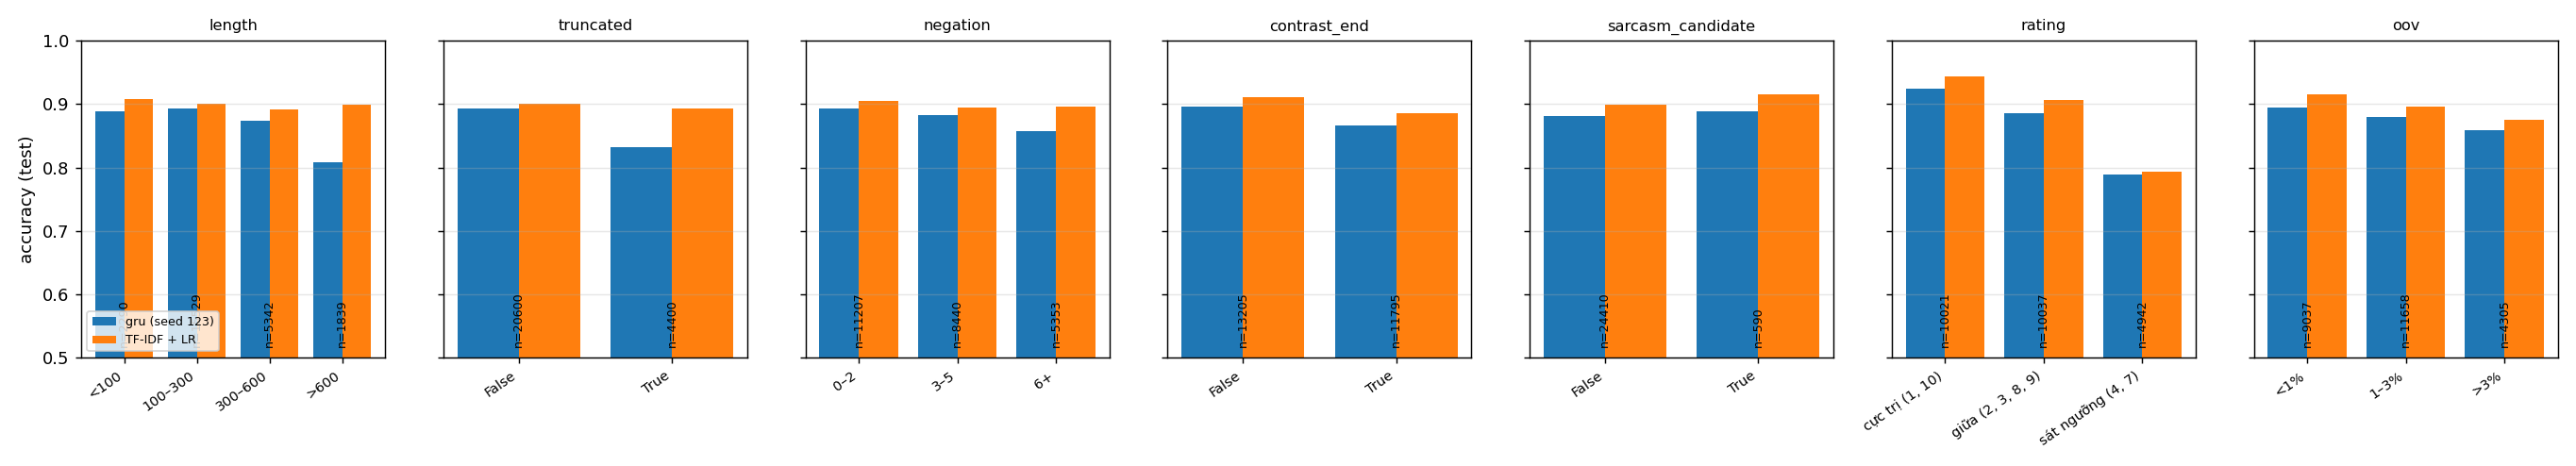

In [17]:
df = None
if BEST_EXP and pred_file(BEST_EXP, "test").exists():
    src_name, df = f"{MODELS[BEST_EXP]} — test", pd.read_csv(pred_file(BEST_EXP, "test"))
elif (PLOTS / "error_analysis" / "acc_by_group.png").exists():
    print("Không có predictions_test.csv trong repo → dùng hình của T2 (tính trên đủ 25.000 review test)")
    show_img(PLOTS / "error_analysis" / "acc_by_group.png", "T2", width=900)
else:
    src_name, df = "M0b TF-IDF + LR — val (tạm, chờ mô hình)", pd.read_csv(pred_file("baseline", "val"))
if df is not None:
    df["correct"] = df["label"] == df["pred"]
    df["n_words"] = df["text"].str.split().str.len()
    df["len_bin"] = pd.cut(df["n_words"], [0, 100, 300, 600, np.inf], labels=["<100", "100–300", "300–600", ">600"])
    df["rating_grp"] = df["rating"].map(lambda r: "sát ngưỡng (4, 7)" if r in (4, 7) else ("cực trị (1, 10)" if r in (1, 10) else "khác"))
    print("Nguồn:", src_name)
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
    for ax, col in zip(axes, ["len_bin", "rating_grp", "rating"]):
        g = df.groupby(col, observed=True)["correct"].agg(["mean", "size"])
        ax.bar(g.index.astype(str), g["mean"])
        for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
            ax.text(i, m, f"{m:.3f}\nn={n}", ha="center", va="bottom", fontsize=8)
        ax.set(title=f"accuracy theo {col}", ylim=(0.5, 1.05))
    plt.tight_layout(); plt.show()

In [18]:
# Lỗi tự tin nhất: mô hình sai nhưng xác suất xa 0,5
src = df[~df["correct"]] if df is not None else pd.read_csv(RES / "error_analysis" / "error_examples.csv")
wrong = src.assign(confidence=lambda d: (d["prob"] - 0.5).abs()).nlargest(5, "confidence").drop_duplicates("uid")
display(wrong[["uid", "label", "rating", "prob", "text"]].assign(text=lambda d: d["text"].str[:300]))

,uid,label,rating,prob,text
50,test_neg_3794,0,4,0.999828,"I went to see this 3 nights ago here in Cork, Ireland. It was the world premiere of it, in the tiny cinema in the Tr..."
30,test_neg_2370,0,4,0.999733,This film derives from a Long Running ITV sitcom by the same name.The Sitcom lasted for half a decade roughly and br...
40,test_neg_12130,0,1,0.999717,This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it a...
60,test_pos_6963,1,8,0.000422,"The lovely, yet lethal Alexandra (stunning statuesque blonde beauty Stacie Randall, who looks absolutely smashing in..."
31,test_neg_7698,0,4,0.999541,"These days, Ridley Scott is one of the top directors and producers and can command huge sums to helm movies--especia..."


### 7.2 Ba mươi câu tự viết

In [19]:
hw = pd.read_csv(ROOT / "data" / "sample" / "handwritten_30.csv")
p = RES / "error_analysis" / "handwritten_30_predictions.csv"
if p.exists():
    hp = pd.read_csv(p)
    display(hp.groupby("case_type").apply(lambda g: (g["label"] == g["pred"]).mean()).rename("accuracy").to_frame())
    display(hp)
else:
    display(pd.crosstab(hw["case_type"], hw["label"]))
    waiting(p, "Thư (T2), cần checkpoint của Đại")

,accuracy
case_type,
mixed,0.2
negation,1.0
negative,1.0
out_of_domain,0.6
positive,0.6
sarcasm,0.4


,text,label,case_type,prob,pred,correct,prob_baseline,pred_baseline,correct_baseline
0,"Every scene feels carefully considered, and the lead actress delivers an emotional performance that made the entire ...",1,positive,0.9634,1,True,0.7116,1,True
1,I loved how the director balanced humor and tension without making either feel forced. The final sequence was especi...,1,positive,0.9958,1,True,0.8334,1,True
2,"The writing is sharp, the soundtrack fits every moment, and the supporting cast brings surprising depth to even the ...",1,positive,0.8616,1,True,0.6280,1,True
3,"From the opening scene to the closing credits, the film kept me completely absorbed. I would happily watch it again.",1,positive,0.2475,0,False,0.7593,1,True
4,Beautiful cinematography and genuinely thoughtful storytelling make this film feel fresh. Nothing about the experien...,1,positive,0.2494,0,False,0.7265,1,True
5,"The plot is painfully predictable, and the characters behave in ways that make absolutely no sense. I struggled to f...",0,negative,0.0073,0,True,0.0427,0,True
6,"Flat dialogue, awkward editing, and lifeless performances turn what could have been an interesting story into a frus...",0,negative,0.0466,0,True,0.0372,0,True
7,"I kept waiting for something meaningful to happen, but the film offered nothing beyond repetitive conversations and ...",0,negative,0.0027,0,True,0.0409,0,True
8,"The soundtrack constantly overwhelms the dialogue, while the poorly developed characters make it impossible to care ...",0,negative,0.1952,0,True,0.0771,0,True
9,"Even the supposedly emotional moments feel artificial. The story lacks direction, and the ending only makes its prob...",0,negative,0.0032,0,True,0.1859,0,True


## 8. Giải thích mô hình

Dùng **occlusion**: che lần lượt từng từ rồi đo xác suất thay đổi bao nhiêu. Kiểm chứng bằng **deletion test**: bỏ k từ quan trọng nhất rồi xem xác suất có giảm nhanh hơn khi bỏ k từ ngẫu nhiên không. Kiểm thêm "đường tắt": mô hình có dựa vào tên diễn viên hoặc độ dài review không. Các hình do `src/eval/explain.py` (T3) tạo.

experiments/plots/explain/deletion_test.png


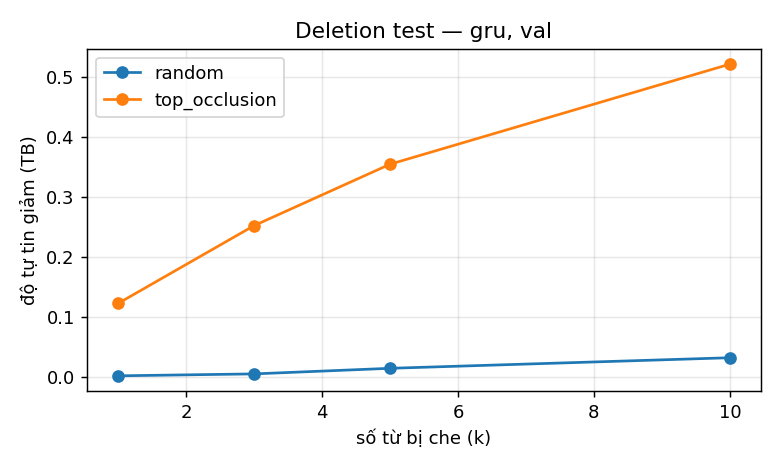

experiments/plots/explain/occlusion_hand_mixed_20.png


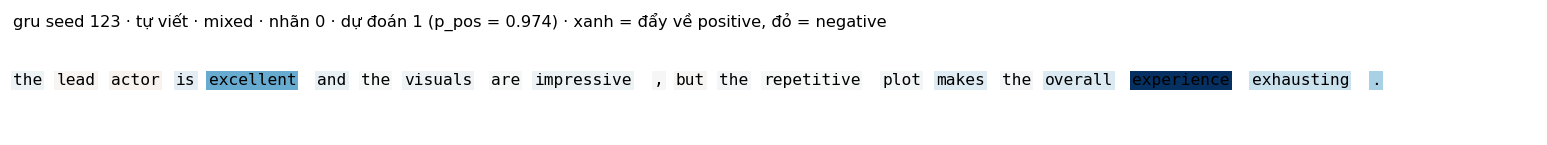

experiments/plots/explain/occlusion_hand_negation_10.png


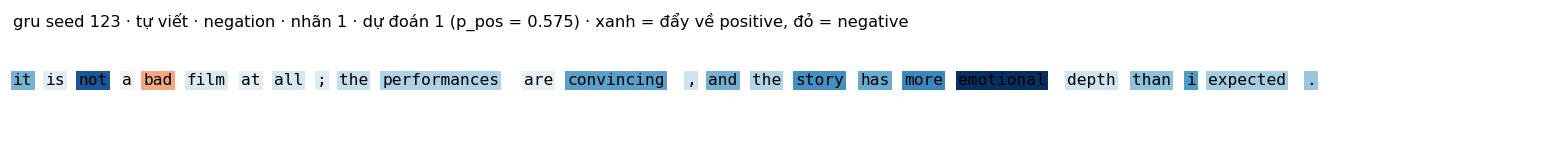

experiments/plots/explain/occlusion_hand_sarcasm_15.png


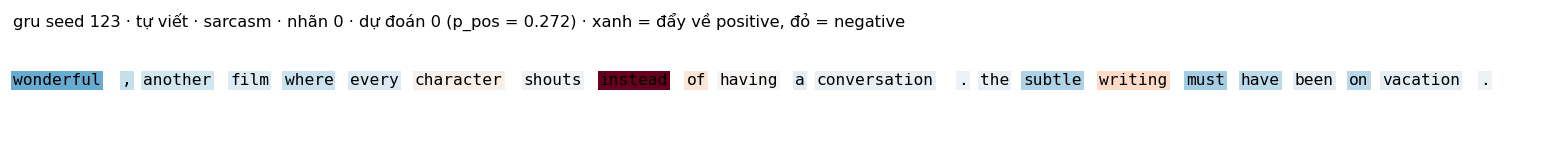

experiments/plots/explain/occlusion_sample_right_test_neg_1847.png


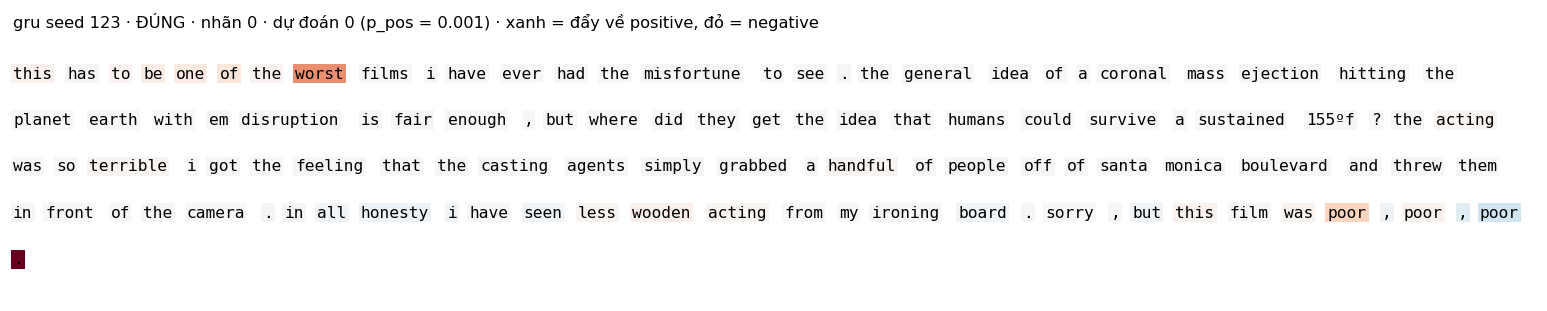

experiments/plots/explain/occlusion_sample_right_test_neg_8858.png


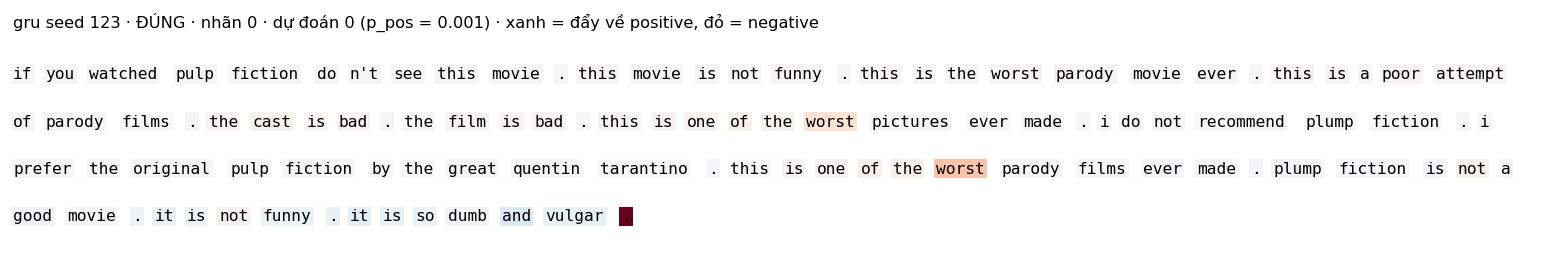

experiments/plots/explain/occlusion_sample_wrong_test_neg_11728.png


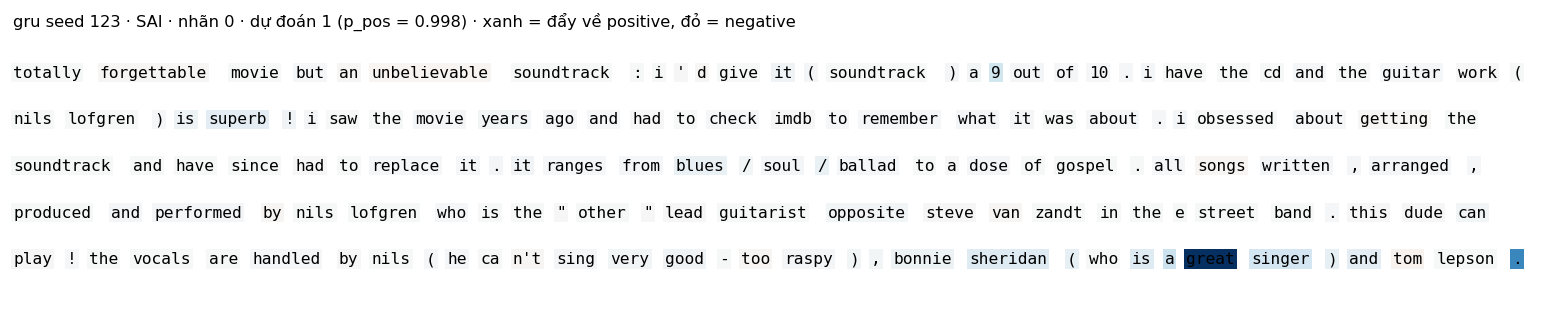

experiments/plots/explain/occlusion_sample_wrong_test_neg_5453.png


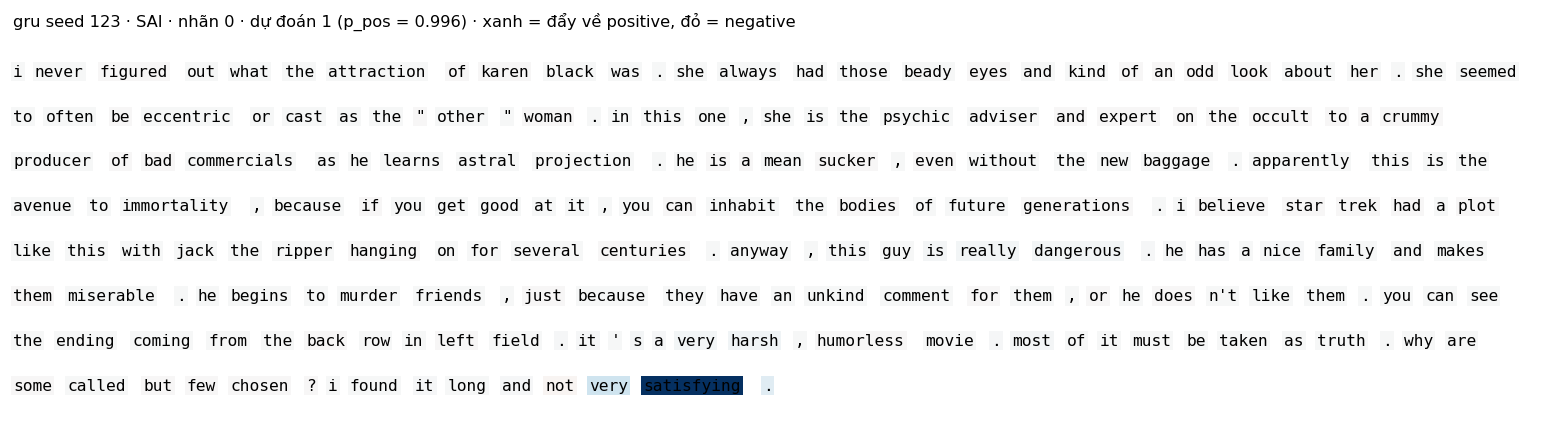

In [20]:
pngs = sorted((PLOTS / "explain").glob("*.png")) if (PLOTS / "explain").exists() else []
for p in pngs:
    print(rel(p)); show_img(p, "Thư (T3)")
if not pngs:
    waiting(PLOTS / "explain", "Thư (T3), cần checkpoint của Đại")

In [21]:
p = RES / "explain" / "summary.json"
if p.exists():
    s = read_json(p)
    print(f"Mô hình: {s['model']} seed {s['seed']} · {s['n_val_reviews']} review val")
    display(Markdown("**Deletion test** — che k từ quan trọng nhất (occlusion) so với k từ ngẫu nhiên"))
    display(pd.DataFrame(s["deletion_test"]).pivot(index="k", columns="how", values=["mean_conf_drop", "flip_rate"]))
    display(Markdown("**Đường tắt tên riêng** (che mọi tên riêng vs che ngẫu nhiên cùng số từ) và **độ dài**"))
    display(pd.Series(s["shortcut_names"]).to_frame("tên riêng"))
    display(pd.Series(s["shortcut_length"]).to_frame("độ dài"))
    tt = RES / "explain" / "top_tokens_val.csv"
    if tt.exists():
        display(Markdown("**Token ảnh hưởng mạnh nhất trung bình trên val** (xuất hiện ≥ 3 lần)"))
        display(pd.read_csv(tt).groupby("direction").head(12))
else:
    waiting(p, "Thư (T3)")

Mô hình: gru seed 123 · 300 review val


**Deletion test** — che k từ quan trọng nhất (occlusion) so với k từ ngẫu nhiên

mean_conf_drop               flip_rate              
how         random top_occlusion    random top_occlusion
k                                                       
1           0.0022        0.1226    0.0067        0.1700
3           0.0054        0.2520    0.0133        0.3000
5           0.0147        0.3542    0.0367        0.3933
10          0.0323        0.5208    0.0533        0.5900

**Đường tắt tên riêng** (che mọi tên riêng vs che ngẫu nhiên cùng số từ) và **độ dài**

,tên riêng
n_reviews,281.0000
mean_tokens_masked,14.9200
names_mean_abs_dprob,0.0690
random_mean_abs_dprob,0.0776
names_flip_rate,0.0641
random_flip_rate,0.0534


,độ dài
n,300.000000
spearman_len_vs_prob_pos,-0.042700
p_value_prob,0.460988
spearman_len_vs_confidence,-0.130100
p_value_conf,0.024275


**Token ảnh hưởng mạnh nhất trung bình trên val** (xuất hiện ≥ 3 lần)

,token,mean_score,count,direction
0,awesome,0.2510,5,positive
1,7,0.2005,12,positive
2,months,0.1712,4,positive
3,abc,0.1587,10,positive
4,ultimately,0.1543,4,positive
5,gorgeous,0.1532,5,positive
6,gentle,0.1531,3,positive
7,fitting,0.1223,4,positive
8,8,0.1163,9,positive
9,core,0.1161,3,positive


## 9. Demo

Dùng hàm `predict(text) -> (label, prob)` trong `src/predict.py` (Bảo, B6). Đây cũng là hàm mà giao diện Gradio `python -m src.demo.app` gọi. Nếu chưa có hàm này thì tạm dùng baseline TF-IDF + LR, nếu trên máy có checkpoint `experiments/checkpoints/baseline_tfidf_lr.joblib`.

In [22]:
DEMO = [
    "I expected nothing and still came away disappointed; the plot falls apart within the first twenty minutes.",
    "Not a bad film at all. The ending surprised me and I would happily watch it again.",
    "The cast is wonderful, but the script gives them nothing to do and the last act is a mess.",
] + pd.read_csv(ROOT / "data" / "sample" / "handwritten_30.csv").groupby("case_type").head(1)["text"].tolist()

try:
    from src.predict import predict
    who = "src.predict"
except ImportError:
    predict, ck = None, EXP / "checkpoints" / "baseline_tfidf_lr.joblib"
    if ck.exists():
        import joblib
        from src.data.clean import clean_text
        bl = joblib.load(ck)
        def predict(text):
            prob = float(bl["model"].predict_proba(bl["vectorizer"].transform([clean_text(text)]))[0, 1])
            return int(prob >= 0.5), prob
        who = "baseline TF-IDF + LR (tạm)"
if predict is None:
    waiting(ROOT / "src" / "predict.py", "Bảo (B6)")
else:
    print("Đang dùng:", who)
    display(pd.DataFrame([(t, *predict(t)) for t in DEMO], columns=["text", "label", "prob"]).round(3))

Đang dùng: src.predict


,text,label,prob
0,I expected nothing and still came away disappointed; the plot falls apart within the first twenty minutes.,0,0.006
1,Not a bad film at all. The ending surprised me and I would happily watch it again.,0,0.257
2,"The cast is wonderful, but the script gives them nothing to do and the last act is a mess.",0,0.013
3,"Every scene feels carefully considered, and the lead actress delivers an emotional performance that made the entire ...",1,0.963
4,"The plot is painfully predictable, and the characters behave in ways that make absolutely no sense. I struggled to f...",0,0.007
5,"It is not a bad film at all; the performances are convincing, and the story has more emotional depth than I expected.",1,0.575
6,"Wonderful, another film where every character shouts instead of having a conversation. The subtle writing must have ...",0,0.272
7,"The lead actor is excellent and the visuals are impressive, but the repetitive plot makes the overall experience exh...",1,0.974
8,"The restaurant has a welcoming atmosphere, the staff are attentive, and every dish arrives fresh and beautifully pre...",1,0.998


,0
checkpoint,gru/seed_123/best.pt
max_len,400
n_reviews,130
ms_median,59.9
ms_p95,96.1
ms_max,199.4
share_under_1s,1.0
tokens_median,159
tokens_max,1235
m5_pass,True


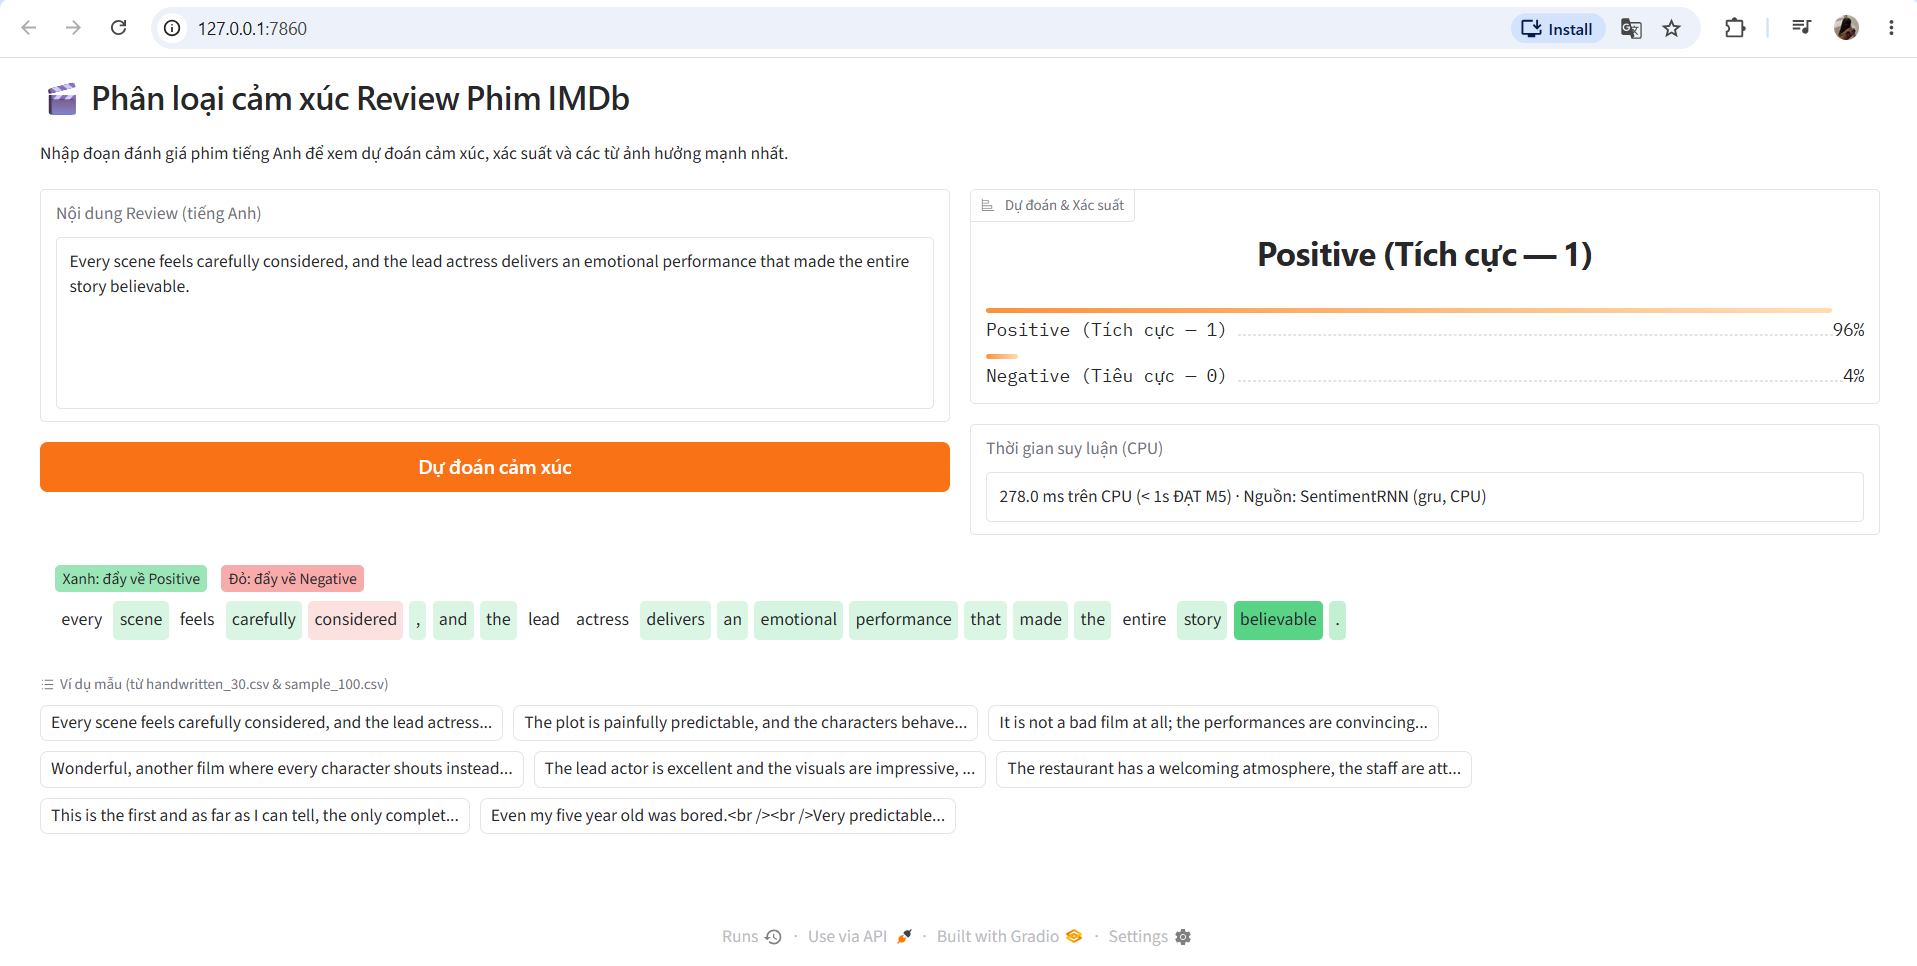

In [23]:
# M5: thời gian demo trên CPU (gồm tô màu từ), đo bằng `python -m src.demo.benchmark`
p = RES / "demo" / "latency.json"
display(pd.json_normalize(read_json(p)).T) if p.exists() else waiting(p, "B6 (benchmark)")
show_img(PLOTS / "demo" / "demo_screenshot.png", "ảnh chụp giao diện Gradio", width=900)

## 10. Giới hạn

- **Mô hình chưa hiểu cấu trúc câu:** trong 50 lỗi lấy ngẫu nhiên, khen chê lẫn lộn chiếm 28%, phủ định 18%, mỉa mai 12%, đổi đối tượng (khen phim khác, nhạc phim…) 12%. Ví dụ ảnh demo thứ hai: câu đổi ý sau "but" bị đoán Positive 97%. Trên 30 câu tự viết, nhóm "vừa khen vừa chê" chỉ đúng 1/5.
- **Cắt độ dài:** với `max_len` = 400 còn 18,7% review train bị cắt; review > 600 token đúng 80,8% (baseline 89,9%). Cắt mất kết luận chỉ còn khoảng 8% lỗi — không còn là nguyên nhân chính.
- **Điểm sát ngưỡng (4, 7):** accuracy 78,9% so với 92,4% ở điểm cực trị (1, 10); baseline cũng chỉ 79,3% — nhiều review loại này tự khen chê lẫn lộn.
- **Nhiễu nhãn và đường tắt:** khoảng 6% lỗi là review có nội dung ngược với điểm người viết tự chấm. Mô hình dùng cả điểm tự ghi trong review ("7", "8" nằm trong nhóm token đẩy mạnh về positive); không dựa vào tên diễn viên (che tên riêng ảnh hưởng ngang che ngẫu nhiên).
- **Dữ liệu phân cực:** IMDb không có review điểm 5–6, nên mô hình không được kiểm trên review trung tính.
- **Test còn review trùng nội bộ:** bước loại trùng chỉ xử lý trùng giữa train và test (vd. `test_pos_12386` = `test_pos_7403`).
- **Một lần chạy, một máy:** mỗi cấu hình 3 seed trên Kaggle T4; ablation `max_len` chỉ 1 seed. Chạy lại theo README cho đúng số (M6), nhưng độ lệch giữa seed (đến ± 0,93 điểm val) lớn hơn một số khác biệt giữa mô hình.
- **Ngoài miền:** chỉ huấn luyện trên review phim tiếng Anh. Kết quả trên review sản phẩm hoặc nhà hàng chỉ mang tính tham khảo.
- **Tham chiếu:** DistilBERT (Lab 3) vẫn cao hơn. LSTM nhẹ và nhanh hơn, nhưng thua về độ chính xác.